In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [ ]:
pip install cartopy geopy geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 34.0 MB/s eta 0:00:00


In [ ]:
data = pd.read_csv('drive/My Drive/PP/drop+interpolate.csv') ## drop+interpolate
data['timestamp'] = pd.to_datetime(data['datetime_utc'])
data.set_index('timestamp', inplace=True)
data = data.reset_index()
data['datetime'] = pd.to_datetime(data['timestamp'])

data['month'] = data['datetime'].dt.month

def get_season(month):
    if month in [3, 4, 5]:
        return 1
    elif month in [6, 7, 8]:
        return 2
    elif month in [9, 10, 11]:
        return 3
    else:
        return 4

data['season'] = data['month'].apply(get_season)
#data['Whale_Status_Code'] = data['humpback'].apply(lambda x: 1 if x == 'present' else 0) ## change to specific species

In [ ]:
data.describe()

,chl_oc3,sst,M_WK_G,M_WK,elevation,depth,temperature,salinity,oxygen_concentration,Whale_Status_Code,lon,lat,month,season
count,4379.000000,4379.000000,4.379000e+03,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000
mean,1.105243,8.914870,2.831561e-01,142.247545,-30.143412,4.374730,8.646938,33.083360,297.087949,0.023750,-74.203459,39.010348,4.840603,3.083352
std,0.740299,4.063654,7.874970e-01,137.291808,11.928502,6.315823,4.219546,0.647287,24.915478,0.152286,0.212472,0.185641,4.155628,1.286911
min,0.124701,4.045817,0.000000e+00,38.000000,-71.000000,1.002332,3.708600,31.002083,214.020000,0.000000,-74.588000,38.510500,1.000000,1.000000
25%,0.638294,5.753998,0.000000e+00,38.000000,-37.000000,1.905440,5.515650,32.623770,275.470000,0.000000,-74.342650,38.925100,2.000000,2.000000
50%,0.969291,6.894989,8.661090e-15,51.000000,-27.000000,2.411583,6.608600,33.088963,302.660000,0.000000,-74.266200,39.035400,3.000000,4.000000
75%,1.326390,12.306573,1.114397e-01,248.000000,-21.000000,3.145955,12.194600,33.590176,318.440000,0.000000,-74.104600,39.138250,11.000000,4.000000
max,8.056715,26.393311,9.336907e+00,455.000000,-11.000000,52.743130,26.791100,34.629738,340.010000,1.000000,-73.565100,39.361300,12.000000,4.000000


In [ ]:
data['Whale_Status_Code'].sum()

np.int64(104)

In [ ]:
import geopandas as gpd
import pandas as pd
import cartopy.io.shapereader as shpreader
from shapely.geometry import Point, LineString
from shapely.ops import nearest_points
import os
from geopy.distance import geodesic
# Load the 10m coastline data from Natural Earth
coastline_shp = shpreader.natural_earth(resolution='10m', category='physical', name='coastline')
coastline_gdf = gpd.read_file(coastline_shp)

# Restrict to the bounding box of interest
#bbox = (-75, 38, -71, 41)
bbox = (-72, 40, -68, 44)
coastline_gdf = coastline_gdf.cx[bbox[0]:bbox[2], bbox[1]:bbox[3]]
# Function to calculate distance from point to nearest coastline
def calculate_distance_to_coastline(point, coastline):
    nearest_geom = nearest_points(point, coastline.unary_union)[1]
    point_coords = (point.y, point.x)  # (latitude, longitude)
    nearest_coords = (nearest_geom.y, nearest_geom.x)  # (latitude, longitude)
    return geodesic(point_coords, nearest_coords).meters / 1000  # return km
geometry = [Point(xy) for xy in zip(data['lon'], data['lat'])]
geo_df = gpd.GeoDataFrame(data, geometry=geometry)
# Calculate distance to coastline
data['distance_to_coastline'] = geo_df['geometry'].apply(calculate_distance_to_coastline, coastline=coastline_gdf)


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/tmp/ipykernel_481/3251035025.py:18: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  nearest_geom = nearest_points(point, coastline.unary_union)[1]


In [ ]:
month_rad = 2*np.pi*data["month"]/12
data["month_sin"] = np.sin(month_rad)
data["month_cos"] = np.cos(month_rad)
# X_pres = data[["M_WK_G","sst","chl_oc3","distance_to_coastline",
#                "month_sin","month_cos"]].to_numpy()

# X_det  = data[["depth","temperature","salinity","oxygen_concentration","elevation","distance_to_coastline"]].to_numpy()
# from sklearn.preprocessing import StandardScaler
# sc_pres = StandardScaler().fit(X_pres)
# sc_det  = StandardScaler().fit(X_det)
# X_pres_z = sc_pres.transform(X_pres)
# X_det_z  = sc_det .transform(X_det)

In [ ]:
time = data['timestamp']
loc = data[['lat','lon']]

In [ ]:
import pandas as pd, numpy as np, torch, torch.nn as nn, time
from sklearn.preprocessing import StandardScaler

In [ ]:
pip install gpytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.2/291.2 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 15.1 MB/s eta 0:00:00


In [ ]:
import gpytorch
class ZIBDatasetRaw(torch.utils.data.Dataset):

    def __init__(self, df, pres_cols, det_cols, scp, scd):
        self.xp = torch.tensor(scp.transform(df[pres_cols]), dtype=torch.float32) ## transform
        self.xd = torch.tensor(scd.transform(df[det_cols ]), dtype=torch.float32)

        lon = torch.tensor(df["lon"].values, dtype=torch.float32)
        lat = torch.tensor(df["lat"].values, dtype=torch.float32)

        # hour-of-year：0…8759 　(24*365−1)
        # hour = (df["datetime"].dt.dayofyear.sub(1)*24 +             # 0 … 8759
        #         df["datetime"].dt.hour).astype(np.float32)
        # hour = torch.tensor(hour.values, dtype=torch.float32)
        month = torch.tensor(df["datetime"].dt.month.values-1, dtype=torch.float32)
        self.st = torch.stack([lon, lat, month], dim=1)              # (N,3)
        self.y  = torch.tensor(df["Whale_Status_Code"].values, dtype=torch.float32)

    def __len__(self):  return len(self.y)
    def __getitem__(self, i):
        return self.xp[i], self.xd[i], self.st[i], self.y[i]

# def build_spatiotemporal_kernel():

#     k_spat = gpytorch.kernels.ScaleKernel(
#                 gpytorch.kernels.RBFKernel(ard_num_dims=1))

#     k_temp = gpytorch.kernels.ScaleKernel(
#                 gpytorch.kernels.PeriodicKernel(period_length=12.0))

#     return k_spat * k_temp
def build_spatiotemporal_kernel():
    base_spat = gpytorch.kernels.RBFKernel(
        ard_num_dims=2,
        active_dims=torch.tensor([0, 1]),
    )
    base_temp = gpytorch.kernels.PeriodicKernel(
        active_dims=torch.tensor([2]),
        period_length=12.0,
    )
    core = gpytorch.kernels.ProductKernel(base_spat, base_temp)
    kernel = gpytorch.kernels.ScaleKernel(core)
    return kernel


class SVGP(gpytorch.models.ApproximateGP):
    def __init__(self, inducing, kernel):
        q = gpytorch.variational.CholeskyVariationalDistribution(inducing.size(0))
        strat = gpytorch.variational.VariationalStrategy(
                    self, inducing, q, learn_inducing_locations=True)
        super().__init__(strat)
        self.mean_module  = gpytorch.means.ConstantMean()
        self.covar_module = kernel
    def forward(self, x):
        return gpytorch.distributions.MultivariateNormal(
                    self.mean_module(x), self.covar_module(x))
class ZIB_MLP_GP_RAW(nn.Module):
    def __init__(self, dim_pres, dim_det, n_induce=512):
        super().__init__()

        self.mlp_pi  = nn.Sequential(nn.Linear(dim_pres,128), nn.ReLU(),
                                     nn.Linear(128,64), nn.ReLU(), nn.Linear(64,32), nn.ReLU(),
                                     nn.Linear(32,16), nn.ReLU(), nn.Linear(16,1))
        self.mlp_phi = nn.Sequential(nn.Linear(dim_det,64), nn.ReLU(),
                                     nn.Linear(64,32), nn.ReLU(), nn.Linear(32,16), nn.ReLU(),
                                    nn.Linear(16,1))

        kernel      = build_spatiotemporal_kernel()
        Z0          = torch.randn(n_induce, 3)
        self.gp_pi  = SVGP(Z0.clone(), kernel)
        #self.gp_phi = SVGP(Z0.clone(), kernel)

        #self.likelihood = gpytorch.likelihoods.BernoulliLikelihood()
        self.apply(xavier_)

    def forward(self, xp_raw, xd_raw, st_raw):
        # st_raw: (N,3)  [lon,lat,hour]
        with gpytorch.settings.fast_pred_var():
            f_pi  = self.gp_pi (st_raw).mean
            #f_phi = self.gp_phi(st_raw).mean
        logit_pi  = self.mlp_pi (xp_raw).squeeze(1) + f_pi
        logit_phi = self.mlp_phi(xd_raw).squeeze(1) #+ f_phi
        return torch.sigmoid(logit_pi), torch.sigmoid(logit_phi)
def xavier_(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)


In [ ]:
import numpy as np, pandas as pd, time, torch
import torch.nn as nn, torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
import random
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark    = False
g = torch.Generator()
g.manual_seed(42)

class ZIBDataset(torch.utils.data.Dataset):
    def __init__(self, df, pres_cols, det_cols,
                 sc_pres:StandardScaler, sc_det:StandardScaler):
        self.xp = torch.from_numpy(sc_pres.transform(df[pres_cols])).float()
        self.xd = torch.from_numpy(sc_det .transform(df[det_cols])).float()
        self.y  = torch.from_numpy(df["Whale_Status_Code"].to_numpy()).float()
    def __len__(self):  return len(self.y)
    def __getitem__(self,i):  return self.xp[i], self.xd[i], self.y[i]

class MLP(nn.Module):
    def __init__(self, d_in, hidden=(128,64,32,16)):
        super().__init__()
        layers=[]
        prev=d_in
        for h in hidden:
            layers += [nn.Linear(prev,h), nn.ReLU()]
            prev=h
        layers += [nn.Linear(prev,1)]
        self.net=nn.Sequential(*layers)
    def forward(self,x): return self.net(x).squeeze(-1)   # raw logit

class ZIB_MLP(nn.Module):
    def __init__(self, d_p, d_d):
        super().__init__()
        self.pres  = nn.Sequential(nn.Linear(d_p,128), nn.ReLU(),
                                     nn.Linear(128,64), nn.ReLU(), nn.Linear(64,32), nn.ReLU(),
                                     nn.Linear(32,16), nn.ReLU(), nn.Linear(16,1))
        self.det = nn.Sequential(nn.Linear(d_d,64), nn.ReLU(),
                                     nn.Linear(64,32), nn.ReLU(), nn.Linear(32,16), nn.ReLU(),
                                    nn.Linear(16,1))
    def forward(self, xp, xd):
        pi  = torch.sigmoid(self.pres(xp))
        phi = torch.sigmoid(self.det (xd))
        return pi, phi

def custom_loss(pi, phi, y, eps=1e-6):

    pi  = pi .clamp(eps, 1-eps)
    phi = phi.clamp(eps, 1-eps)
    y   = y.float()

    w = (pi * (1 - phi)) / ((1 - pi) + pi * (1 - phi) + eps)
    w = w.clamp(eps, 1 - eps).detach()

    loss1 = (
        - y       * torch.log(pi)
        - (1 - y) * ( w * torch.log(pi) + (1 - w) * torch.log(1 - pi) )
    ).mean()
    loss2 = (
        - y       * torch.log(phi)
        - (1 - y) * w * torch.log(1 - phi)
    ).mean()
    total_loss = loss1 + loss2
    return total_loss, loss1, loss2


# def custom_loss(pi, phi, y, eps=1e-8):

#     pi  = pi .clamp(eps, 1-eps)
#     phi = phi.clamp(eps, 1-eps)
#     p1 = pi * phi
#     p0 = (1 - pi) + pi * (1 - phi)
#     loss1 = (y * torch.log(p1)).mean()
#     loss2 = ((1 - y) * torch.log(p0)).mean()
#     total = loss1 + loss2
#     return -total, loss1, loss2

def train_one_sim(df_sim, pres_cols, det_cols,
                  sc_pres, sc_det,
                  epoch=400, lr=3e-4, batch=512,
                  patience=20, verbose=False, SEED = 42):
    torch.manual_seed(SEED)
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    g = torch.Generator()
    g.manual_seed(SEED)

    # Dataset & DataLoader
    ds = ZIBDataset(df_sim, pres_cols, det_cols, sc_pres, sc_det)
    dl = torch.utils.data.DataLoader(ds, batch_size=batch,
                                     shuffle=True, num_workers=0, generator=g)

    net = ZIB_MLP(len(pres_cols), len(det_cols))
    opt = torch.optim.Adam(net.parameters(), lr=lr)

    best_loss, stall = 1e9, 0
    best_state = None
    tic = time.time()

    for ep in range(1, epoch + 1):
        net.train()
        total_loss = 0.0

        for xp, xd, y in dl:
            opt.zero_grad()
            pi, phi = net(xp, xd)
            loss, _, _ = custom_loss(pi, phi, y)
            loss.backward()
            opt.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(dl)

        if verbose and ep % 20 == 0:
            print(f"ep {ep:3d} | avg loss = {avg_loss:.4f}")

        if avg_loss < best_loss - 1e-4:
            best_loss = avg_loss
            best_state = net.state_dict()
            stall = 0
        else:
            stall += 1

        if stall >= patience:
            if verbose:
                print("Early stopping.")
            break

    if best_state is None:
        best_state = net.state_dict()

    return best_state, best_loss, time.time() - tic



In [ ]:
import gpytorch
from gpytorch.mlls.variational_elbo import VariationalELBO
from torch.utils.data import DataLoader

def train_one_sim_gp_raw(df_sim, pres_cols, det_cols, sc_pres, sc_det,
                         epoch=100, lr=1e-3, batch=512, patience=20, verbose=True, SEED=42):
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)

    g = torch.Generator()
    g.manual_seed(SEED)

    # Dataset & Loader
    ds = ZIBDatasetRaw(df_sim, pres_cols, det_cols, sc_pres, sc_det)
    dl = DataLoader(ds, batch_size=batch, shuffle=True, num_workers=0, generator=g)

    model = ZIB_MLP_GP_RAW(len(pres_cols), len(det_cols), n_induce=512)
    model.train()
    likelihood = gpytorch.likelihoods.GaussianLikelihood()
    mll_gp = VariationalELBO(likelihood, model.gp_pi, num_data=len(ds))

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss, stall = 1e9, 0
    tic = time.time()

    for ep in range(1, epoch + 1):
        model.train()
        total_loss = 0

        for xp, xd, st, y in dl:
            optimizer.zero_grad()
            pi, phi = model(xp, xd, st)

            loss_custom, _, _ = custom_loss(pi, phi, y)

            # GP KL loss
            output = model.gp_pi(st)
            loss_gp = -mll_gp(output, torch.zeros_like(y))

            # Combine
            loss = loss_custom + loss_gp
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(dl)
        if verbose and ep % 10 == 0:
            print(f"Epoch {ep:3d} | Loss = {avg_loss:.4f}")

        if avg_loss < best_loss - 1e-4:
            best_loss, stall = avg_loss, 0
            best_state = model.state_dict()
        else:
            stall += 1

        if stall >= patience:
            print("Early stopping.")
            break

    return best_state, best_loss, time.time() - tic


In [ ]:
import time, numpy as np, torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, brier_score_loss

class ZIBLogit(nn.Module):
    def __init__(self, dp, dd):
        super().__init__()
        self.alpha = nn.Linear(dp, 1, bias=True)   # π
        self.beta  = nn.Linear(dd, 1, bias=True)   # φ
    def forward(self, xp, xd):
        pi  = torch.sigmoid(self.alpha(xp)).squeeze(-1)
        phi = torch.sigmoid(self.beta (xd)).squeeze(-1)
        return pi, phi

class _MLP(nn.Module):
    def __init__(self, d_in, hidden=(64,32)):
        super().__init__()
        layers=[]; prev=d_in
        for h in hidden:
            layers += [nn.Linear(prev,h), nn.ReLU()]
            prev=h
        layers += [nn.Linear(prev,1)]
        self.net = nn.Sequential(*layers)
    def forward(self,x): return self.net(x).squeeze(-1)

class ZIB_MLP(nn.Module):
    def __init__(self, dp, dd, hp=(128,64,32,16), hd=(64,32,16)):
        super().__init__()
        self.pres = _MLP(dp, hp)
        self.det  = _MLP(dd, hd)
    def forward(self, xp, xd):
        pi  = torch.sigmoid(self.pres(xp))
        phi = torch.sigmoid(self.det (xd))
        return pi, phi

def marginal_nll(pi, phi, y, eps=1e-12):
    q1 = (pi*phi).clamp(eps, 1-eps)
    q0 = (1 - pi*phi).clamp(eps, 1-eps)
    return -(y*torch.log(q1) + (1-y)*torch.log(q0)).mean()

def _metrics_overall_and_pos(y_true, q_prob):
    y = np.asarray(y_true, int)
    q = np.clip(np.asarray(q_prob, float), 1e-12, 1-1e-12)
    # overall
    nll_all   = float(log_loss(y, q))
    brier_all = float(brier_score_loss(y, q))
    # positive-only
    pos = (y == 1)
    if pos.any():
        nll_pos   = float(-np.log(q[pos]).mean())
        brier_pos = float(((q[pos]-1.0)**2).mean())
    else:
        nll_pos = np.nan; brier_pos = np.nan
    return nll_all, brier_all, nll_pos, brier_pos

def fit_zib_and_score(
    train_df, test_df, PRES, DET,
    label_col="Whale_Status_Code",
    model="logit",              # "logit" 或 "mlp"
    epoch=300, lr=3e-4, batch=512,
    patience=20, verbose=True, seed=42
):
    torch.manual_seed(seed); np.random.seed(seed)

    scp = StandardScaler().fit(train_df[PRES])
    scd = StandardScaler().fit(train_df[DET ])

    def _xy(df):
        xp = torch.from_numpy(scp.transform(df[PRES])).float()
        xd = torch.from_numpy(scd.transform(df[DET ])).float()
        y  = torch.tensor(df[label_col].to_numpy(), dtype=torch.float32)
        return xp, xd, y

    xp_tr, xd_tr, y_tr = _xy(train_df)
    xp_te, xd_te, y_te = _xy(test_df)

    if model == "logit":
        net = ZIBLogit(len(PRES), len(DET))
        opt = torch.optim.LBFGS(
            net.parameters(), lr=1.0, max_iter=100, history_size=20,
            line_search_fn="strong_wolfe", tolerance_change=1e-12
        )
        best = np.inf; best_state=None; stall=0; tic=time.time()
        for ep in range(1, epoch+1):
            def closure():
                opt.zero_grad()
                pi, phi = net(xp_tr, xd_tr)
                loss = marginal_nll(pi, phi, y_tr)
                loss.backward()
                return loss
            nll = opt.step(closure).item()
            if nll < best - 1e-9:
                best, stall = nll, 0
                best_state = {k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
            else:
                stall += 1
            if verbose and ep % 10 == 0:
                print(f"[LBFGS ep {ep:03d}] train NLL={nll:.6f}")
            if stall >= patience:
                if verbose: print("Early stopped.");
                break
        if best_state is not None:
            net.load_state_dict(best_state)
        train_time = time.time()-tic

    else:
        net = ZIB_MLP(len(PRES), len(DET))
        dl = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(xp_tr, xd_tr, y_tr),
            batch_size=batch, shuffle=True
        )
        opt = torch.optim.Adam(net.parameters(), lr=lr)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
            opt, mode="min", factor=0.5, patience=8, threshold=1e-4
        )
        best = np.inf; best_state=None; stall=0; tic=time.time()
        for ep in range(1, epoch+1):
            net.train()
            for xb_p, xb_d, yb in dl:
                opt.zero_grad()
                loss = marginal_nll(*net(xb_p, xb_d), yb)
                loss.backward(); opt.step()
            with torch.no_grad():
                net.eval()
                pi_full, phi_full = net(xp_tr, xd_tr)
                full_loss = marginal_nll(pi_full, phi_full, y_tr).item()
            sched.step(full_loss)
            if full_loss < best - 1e-6:
                best, stall = full_loss, 0
                best_state = {k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
            else:
                stall += 1
            if verbose and ep % 20 == 0:
                print(f"[Adam ep {ep:03d}] train NLL={full_loss:.6f}")
            if stall >= patience:
                if verbose: print("Early stopped.");
                break
        if best_state is not None:
            net.load_state_dict(best_state)
        train_time = time.time()-tic

    net.eval()
    with torch.no_grad():
        pi_tr, phi_tr = net(xp_tr, xd_tr); q_tr = (pi_tr*phi_tr).cpu().numpy()
        pi_te, phi_te = net(xp_te, xd_te); q_te = (pi_te*phi_te).cpu().numpy()

    y_tr_np = y_tr.cpu().numpy().astype(int)
    y_te_np = y_te.cpu().numpy().astype(int)

    tr_nll_all, tr_brier_all, tr_nll_pos, tr_brier_pos = _metrics_overall_and_pos(y_tr_np, q_tr)
    te_nll_all, te_brier_all, te_nll_pos, te_brier_pos = _metrics_overall_and_pos(y_te_np, q_te)
    te_auc = roc_auc_score(y_te_np, q_te)
    metrics = {
        "train_NLL_all": tr_nll_all,   "train_Brier_all": tr_brier_all,
        "train_NLL_pos": tr_nll_pos,   "train_Brier_pos": tr_brier_pos,
        "test_NLL_all" : te_nll_all,   "test_Brier_all" : te_brier_all,
        "test_NLL_pos" : te_nll_pos,   "test_Brier_pos" : te_brier_pos,
        "test_auc": te_auc,
        "train_time_sec": float(train_time),
        "best_train_NLL": float(best)
    }
    test_df['pi'] = pi_te.cpu().numpy()
    df = test_df.copy()
    return net.state_dict(), metrics, (scp, scd), df


In [ ]:

# PRES = ["M_WK_G","sst","chl_oc3","distance_to_coastline","month_sin","month_cos"]
# DET  = ["depth","temperature","salinity","oxygen_concentration","elevation","distance_to_coastline"]

# state_dict, mets, (sc_pres, sc_det), full = fit_zib_and_score(
#     df_train, test_df, PRES, DET,
#     label_col="Whale_Status_Code",
#     model="logit",
#     seed=42
# )


In [ ]:
# df_sim = data.copy()
# test_df = df_sim[df_sim['timestamp'] >= '2022-02-01']
# df_train = df_sim[df_sim['timestamp'] < '2022-02-01'] ##  03 : 3579/4379

In [ ]:
# present = test_df[test_df['Whale_Status_Code']==1]
# print(-float(np.mean(np.log(np.clip(present['pi'], 1e-12, 1.0)))))
# float(np.mean((present['pi'] - 1.0)**2))

In [ ]:
data.describe()

,chl_oc3,sst,M_WK_G,M_WK,elevation,depth,temperature,salinity,oxygen_concentration,Whale_Status_Code,lon,lat,month,season,distance_to_coastline,month_sin,month_cos
count,4379.000000,4379.000000,4.379000e+03,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4379.000000,4.379000e+03,4.379000e+03
mean,1.105243,8.914870,2.831561e-01,142.247545,-30.143412,4.374730,8.646938,33.083360,297.087949,0.023750,-74.203459,39.010348,4.840603,3.083352,41.628931,5.431670e-01,4.540275e-01
std,0.740299,4.063654,7.874970e-01,137.291808,11.928502,6.315823,4.219546,0.647287,24.915478,0.152286,0.212472,0.185641,4.155628,1.286911,24.641898,5.097410e-01,4.889853e-01
min,0.124701,4.045817,0.000000e+00,38.000000,-71.000000,1.002332,3.708600,31.002083,214.020000,0.000000,-74.588000,38.510500,1.000000,1.000000,7.567353,-8.660254e-01,-1.000000e+00
25%,0.638294,5.753998,0.000000e+00,38.000000,-37.000000,1.905440,5.515650,32.623770,275.470000,0.000000,-74.342650,38.925100,2.000000,2.000000,24.572313,-2.449294e-16,6.123234e-17
50%,0.969291,6.894989,8.661090e-15,51.000000,-27.000000,2.411583,6.608600,33.088963,302.660000,0.000000,-74.266200,39.035400,3.000000,4.000000,35.028588,8.660254e-01,5.000000e-01
75%,1.326390,12.306573,1.114397e-01,248.000000,-21.000000,3.145955,12.194600,33.590176,318.440000,0.000000,-74.104600,39.138250,11.000000,4.000000,49.326532,8.660254e-01,8.660254e-01
max,8.056715,26.393311,9.336907e+00,455.000000,-11.000000,52.743130,26.791100,34.629738,340.010000,1.000000,-73.565100,39.361300,12.000000,4.000000,115.337416,1.000000e+00,1.000000e+00


In [ ]:
train_df

,timestamp,chl_oc3,sst,M_WK_G,datetime_utc,M_WK,elevation,depth,temperature,salinity,oxygen_concentration,Whale_Status_Code,lon,lat,datetime,month,season,distance_to_coastline,month_sin,month_cos
0,2020-11-20 10:45:16+00:00,3.047778,15.257978,1.082735e-01,2020-11-20 10:45:16+00:00,38.0,-26.0,2.193203,14.5741,31.990088,250.98,1,-74.1587,39.2727,2020-11-20 10:45:16+00:00,11,3,23.885011,-0.5,0.866025
1,2020-11-22 02:29:09+00:00,0.835666,15.778320,1.744130e-01,2020-11-22 02:29:09+00:00,38.0,-23.0,2.788662,14.7752,32.260773,250.45,1,-74.1812,39.1810,2020-11-22 02:29:09+00:00,11,3,28.000095,-0.5,0.866025
2,2020-11-22 03:00:16+00:00,0.763327,15.822998,1.646124e-01,2020-11-22 03:00:16+00:00,248.0,-23.0,1.826033,14.8638,32.208557,260.78,1,-74.1829,39.1789,2020-11-22 03:00:16+00:00,11,3,28.059398,-0.5,0.866025
3,2020-11-22 03:30:16+00:00,0.728270,15.822998,1.278443e-01,2020-11-22 03:30:16+00:00,418.0,-23.0,2.540563,14.8565,32.208710,257.37,1,-74.1818,39.1764,2020-11-22 03:30:16+00:00,11,3,28.322970,-0.5,0.866025
4,2020-11-22 03:45:16+00:00,0.713434,15.822998,1.117134e-01,2020-11-22 03:45:16+00:00,248.0,-23.0,4.287182,14.8170,32.254642,250.58,1,-74.1812,39.1752,2020-11-22 03:45:16+00:00,11,3,28.454070,-0.5,0.866025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3029,2022-01-31 20:09:04+00:00,2.519341,6.605408,5.617598e-13,2022-01-31 20:09:04+00:00,51.0,-20.0,2.649734,4.5891,32.624960,311.88,0,-74.2137,39.1478,2022-01-31 20:09:04+00:00,1,4,28.936405,0.5,0.866025
3030,2022-01-31 21:09:04+00:00,2.128976,7.057969,3.948842e-13,2022-01-31 21:09:04+00:00,51.0,-24.0,2.292468,4.5082,32.634724,314.05,0,-74.2241,39.1510,2022-01-31 21:09:04+00:00,1,4,28.120611,0.5,0.866025
3031,2022-01-31 22:09:04+00:00,2.851553,6.944584,3.346100e-13,2022-01-31 22:09:04+00:00,51.0,-23.0,2.649733,4.5082,32.634724,314.05,0,-74.2360,39.1551,2022-01-31 22:09:04+00:00,1,4,27.158998,0.5,0.866025
3032,2022-01-31 23:09:04+00:00,2.866361,6.562311,5.241240e-13,2022-01-31 23:09:04+00:00,51.0,-24.0,3.016920,4.5082,32.634724,314.05,0,-74.2465,39.1577,2022-01-31 23:09:04+00:00,1,4,26.415898,0.5,0.866025


In [ ]:
import numpy as np, pandas as pd, torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

df_sim = data.copy()

train_df = df_sim[df_sim['timestamp'] < '2022-02-01']

PRES = ["sst","chl_oc3","distance_to_coastline",
        "month_sin","month_cos"]
#PRES = ["M_WK_G","sst","chl_oc3","distance_to_coastline"]
DET  = ["depth","temperature","salinity","oxygen_concentration",
        "elevation","distance_to_coastline"]
sc_pres = StandardScaler().fit(train_df[PRES])
sc_det  = StandardScaler().fit(train_df[DET ])

state_dict, best_loss, sec = train_one_sim_gp_raw(
        train_df, PRES, DET,
        sc_pres, sc_det,
        epoch=25, lr=6e-4, batch=256,
        patience=20, verbose=True, SEED = 42)
print(f"training time = {sec:.2f}s, best_loss = {best_loss:.4f}")


Epoch  10 | Loss = 1.6188
Epoch  20 | Loss = 1.5185
training time = 88.45s, best_loss = 1.4538


In [ ]:
import torch
import joblib
import os

save_dir = "drive/MyDrive/NARW/deepzib_withoutfront_saved_model"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "state_dict": state_dict,
    "best_loss": best_loss,
    "training_time_sec": sec,
    "PRES": PRES,
    "DET": DET,
    "n_pres": len(PRES),
    "n_det": len(DET),
    "seed": 42,
    "epoch": 25,
    "lr": 6e-4,
    "batch": 256,
}, os.path.join(save_dir, "deepzib_model.pt"))

joblib.dump(sc_pres, os.path.join(save_dir, "sc_pres.pkl"))
joblib.dump(sc_det, os.path.join(save_dir, "sc_det.pkl"))

print("Model and scalers saved.")

Model and scalers saved.


In [ ]:
model = ZIB_MLP_GP_RAW(len(PRES), len(DET))
model.load_state_dict(state_dict)
model.eval()
test_df = df_sim[df_sim['timestamp'] >= '2022-02-01']
#test_df = df_sim
xp = torch.from_numpy(sc_pres.transform(test_df[PRES])).float()
xd = torch.from_numpy(sc_det .transform(test_df[DET ])).float()
lon   = torch.tensor(test_df["lon"].values, dtype=torch.float32)
lat   = torch.tensor(test_df["lat"].values, dtype=torch.float32)
month = torch.tensor((test_df["datetime"].dt.month - 1).values, dtype=torch.float32)
st    = torch.stack([lon, lat, month], dim=1)
with torch.no_grad():
    pi, phi = model(xp, xd,st)
    y_prob  = (pi*phi).cpu().numpy()      # P(Y=1)
    y_true  = test_df["Whale_Status_Code"].to_numpy()

print("Test NLL   :", log_loss(y_true, y_prob))
print("Test AUC   :", roc_auc_score(y_true, y_prob))
print("Test Brier :", brier_score_loss(y_true, y_prob))
test_df['pi'] = pi.cpu().numpy()

Test NLL   : 0.08463865683845333
Test AUC   : 0.8145755885997521
Test Brier : 0.016541906209390746


/tmp/ipykernel_481/2247540632.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df['pi'] = pi.cpu().numpy()


In [ ]:
#test_df['pi'] = pi.cpu().numpy()
present = test_df[test_df['Whale_Status_Code']==1]
print(-float(np.mean(np.log(np.clip(present['pi'], 1e-12, 1.0)))))
float(np.mean((present['pi'] - 1.0)**2))


2.6474640369415283


0.7944186329841614

In [ ]:
import xarray as xr
import pandas as pd

vars_needed = ['sst', 'chl_oc3', 'M_WK_G']
nc_path = 'drive/My Drive/PP/satellite_data_monthly.nc'

ds = xr.open_dataset(nc_path)

dfs = []

if 'time' in ds.dims:
    for t in ds['time'].values:
        da_slice = ds.sel(time=t)
        date_str = str(pd.to_datetime(t).date())

        tmp = xr.Dataset({v: da_slice[v] for v in vars_needed}
                         ).to_dataframe().reset_index()
        tmp['time'] = date_str
        dfs.append(tmp)

else:
    date_str = 'unknown'
    tmp = xr.Dataset({v: ds[v] for v in vars_needed}
                     ).to_dataframe().reset_index()
    tmp['time'] = date_str
    dfs.append(tmp)

big_df = pd.concat(dfs, ignore_index=True)

big_df.rename(columns={'longitude': 'lon_center',
                       'latitude' : 'lat_center'}, inplace=True)

print('shape:', big_df.shape)
print(big_df.head())


shape: (251262, 6)
   lon_center  lat_center        time       sst   chl_oc3    M_WK_G
0       -75.0       38.40  2022-01-01  6.191052  3.792777  0.299195
1       -75.0       38.41  2022-01-01  5.996184  3.629930  0.553387
2       -75.0       38.42  2022-01-01  5.824342  3.461703  0.696629
3       -75.0       38.43  2022-01-01  5.812895  3.501650  0.000000
4       -75.0       38.44  2022-01-01  5.878420  3.650300  1.165032


In [ ]:
big_df = big_df[(big_df.sst.between(0, 27)) &
        (big_df.chl_oc3.between(0,5.2))]

In [ ]:
import pandas as pd
from datetime import datetime
big_df['date'] = pd.to_datetime(big_df['time'])
mask_2020 = big_df['date'].dt.year == 2020
df_2020   = big_df.loc[mask_2020].copy()
season_map = {12:4, 1:4, 2:4,
               3:1, 4:1, 5:1,
               6:2, 7:2, 8:2,
               9:3,10:3,11:3}
df_2020['season'] = df_2020['date'].dt.month.map(season_map)

mask_2021 = big_df['date'].dt.year == 2021
df_2021   = big_df.loc[mask_2021].copy()

df_2021['season'] = df_2021['date'].dt.month.map(season_map)

mask_2022 = big_df['date'].dt.year == 2022
df_2022   = big_df.loc[mask_2022].copy()

df_2022['season'] = df_2022['date'].dt.month.map(season_map)


In [ ]:
f1 = df_2022[(df_2022['date'] == '2022-02-01')].copy()
f1['month_selected']= 2*np.ones(len(f1))

In [ ]:
month_rad = 2*np.pi*f1["month_selected"]/12
f1["month_sin"] = np.sin(month_rad)
f1["month_cos"] = np.cos(month_rad)

In [ ]:
geometry = [Point(xy) for xy in zip(f1['lon_center'], f1['lat_center'])]
geo_df = gpd.GeoDataFrame(f1, geometry=geometry)
# Calculate distance to coastline
f1['distance_to_coastline'] = geo_df['geometry'].apply(calculate_distance_to_coastline, coastline=coastline_gdf)

/tmp/ipykernel_481/3251035025.py:18: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  nearest_geom = nearest_points(point, coastline.unary_union)[1]


In [ ]:
f1['month_selected'].values

array([2., 2., 2., ..., 2., 2., 2.])

# UQ

In [24]:
import numpy as np
import pandas as pd
import os


def add_trial_id(
    df,
    time_col="datetime_utc",
    gap_days=7,
    trial_col="trial_id"
):
    """
    Identify separate glider trials/deployments using large
    gaps in observation time.

    A new trial begins whenever the gap between two consecutive
    observations exceeds `gap_days`.
    """

    out = df.copy()

    # ----------------------------------------
    # 1. Make sure datetime_utc is datetime
    # ----------------------------------------
    out[time_col] = pd.to_datetime(
        out[time_col],
        errors="coerce"
    )

    if out[time_col].isna().any():
        raise ValueError(
            f"{time_col} contains missing/invalid datetime values."
        )

    # ----------------------------------------
    # 2. Temporarily sort chronologically
    # ----------------------------------------
    original_index = out.index

    out = out.sort_values(
        time_col
    ).copy()

    # ----------------------------------------
    # 3. Calculate time gap between
    #    consecutive observations
    # ----------------------------------------
    gap = out[time_col].diff()

    # ----------------------------------------
    # 4. New trial if gap > gap_days
    # ----------------------------------------
    new_trial = (
        gap > pd.Timedelta(days=gap_days)
    )

    # first observation belongs to trial 0
    new_trial = new_trial.fillna(False)

    # cumulative sum:
    # False False True False True
    # becomes
    #   0     0    1    1    2
    out[trial_col] = (
        new_trial.cumsum()
    )

    # ----------------------------------------
    # 5. Restore original dataframe ordering
    # ----------------------------------------
    out = out.sort_index()

    return out

In [25]:
train_df = add_trial_id(
    train_df,
    time_col="datetime_utc",
    gap_days=7,
    trial_col="trial_id"
)

In [26]:
def prepare_time_blocks(
    train_df,
    trial_col="trial_id",
    time_col="datetime_utc",
    block_hours=24
):
    """
    Pre-compute candidate moving blocks for one training fold.

    This function should be called ONCE per CV fold.

    Returns
    -------
    prepared_trials : list of dictionaries

        For each trial, stores:
        - chronologically sorted dataframe
        - target sample size
        - candidate block position arrays
    """

    df = train_df.copy()

    # -----------------------------------------
    # Check required columns
    # -----------------------------------------
    for col in [trial_col, time_col]:
        if col not in df.columns:
            raise KeyError(
                f"Required column '{col}' not found."
            )

    # -----------------------------------------
    # Ensure datetime format
    # -----------------------------------------
    df[time_col] = pd.to_datetime(
        df[time_col],
        errors="coerce"
    )

    if df[time_col].isna().any():
        raise ValueError(
            f"{time_col} contains invalid datetime values."
        )

    block_delta = pd.Timedelta(
        hours=block_hours
    )

    prepared_trials = []

    # =========================================
    # Prepare each trial once
    # =========================================
    for trial_id, trial_df in df.groupby(
        trial_col,
        sort=False
    ):

        # chronological ordering
        trial_df = (
            trial_df
            .sort_values(time_col)
            .reset_index(drop=True)
        )

        n_target = len(trial_df)

        if n_target == 0:
            continue

        # Convert timestamps to numpy datetime64
        times = (
            trial_df[time_col]
            .to_numpy()
        )

        candidate_blocks = []

        last_time = times[-1]

        # =====================================
        # Candidate moving blocks
        # =====================================
        for start_idx in range(n_target):

            start_time = times[start_idx]

            end_time = (
                start_time
                + np.timedelta64(
                    block_hours,
                    "h"
                )
            )

            # Require full 24-hour window
            if end_time > last_time:
                break

            # ---------------------------------
            # Find first index >= end_time
            #
            # Much faster than repeatedly doing:
            #
            # trial_df[
            #   (time >= start) &
            #   (time < end)
            # ]
            # ---------------------------------
            end_idx = np.searchsorted(
                times,
                end_time,
                side="left"
            )

            # positions:
            # start_idx, ..., end_idx-1
            block_positions = np.arange(
                start_idx,
                end_idx,
                dtype=np.int32
            )

            if len(block_positions) > 0:
                candidate_blocks.append(
                    block_positions
                )

        # -------------------------------------
        # Fallback for a trial shorter than
        # block_hours
        # -------------------------------------
        if len(candidate_blocks) == 0:

            candidate_blocks = [
                np.arange(
                    n_target,
                    dtype=np.int32
                )
            ]

        prepared_trials.append(
            {
                "trial_id":
                    trial_id,

                "trial_df":
                    trial_df,

                "n_target":
                    n_target,

                "candidate_blocks":
                    candidate_blocks
            }
        )

    return prepared_trials

In [27]:
prepared_trials = prepare_time_blocks(
    train_df=train_df,
    trial_col="trial_id",
    time_col="datetime_utc",
    block_hours=24
)

In [28]:
def sample_prepared_time_blocks(
    prepared_trials,
    random_state=42
):
    """
    Generate ONE block-bootstrap sample from
    pre-computed candidate blocks.

    The candidate blocks themselves are NOT rebuilt.
    """

    rng = np.random.default_rng(
        random_state
    )

    boot_trials = []

    # =========================================
    # Resample each trial separately
    # =========================================
    for info in prepared_trials:

        trial_df = info["trial_df"]

        n_target = info["n_target"]

        candidate_blocks = (
            info["candidate_blocks"]
        )

        sampled_positions = []

        n_sampled = 0

        # =====================================
        # Sample blocks with replacement
        # =====================================
        while n_sampled < n_target:

            block_idx = rng.integers(
                0,
                len(candidate_blocks)
            )

            positions = (
                candidate_blocks[
                    block_idx
                ]
            )

            sampled_positions.append(
                positions
            )

            n_sampled += len(
                positions
            )

        # =====================================
        # Combine positional indices
        # =====================================
        sampled_positions = np.concatenate(
            sampled_positions
        )

        # trim to original trial size
        sampled_positions = (
            sampled_positions[:n_target]
        )

        # =====================================
        # Select rows
        # =====================================
        boot_trial = (
            trial_df
            .iloc[sampled_positions]
            .copy()
        )

        boot_trials.append(
            boot_trial
        )

    # =========================================
    # Combine trials
    # =========================================
    boot_df = pd.concat(
        boot_trials,
        ignore_index=True
    )

    return boot_df

In [29]:
PRES

['sst', 'chl_oc3', 'distance_to_coastline', 'month_sin', 'month_cos']

In [30]:
import os
import time
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

# ============================================================
# Settings
# ============================================================
K = 200
base_seed = 10000

out_dir = "drive/MyDrive/Research/MS/real_data_block_bootstrap_gp_raw_withoutfront"
os.makedirs(out_dir, exist_ok=True)

pred_dir = os.path.join(out_dir, "predictions")
model_dir = os.path.join(out_dir, "models")

os.makedirs(pred_dir, exist_ok=True)
os.makedirs(model_dir, exist_ok=True)

n = len(train_df)

pi_boot = []

for k in range(K):

    print("\n" + "=" * 70)
    print(f"Bootstrap {k + 1}/{K}")
    print("=" * 70)

    start_k = time.time()
    seed_k = base_seed + k
    rng = np.random.default_rng(seed_k)

    boot_df = sample_prepared_time_blocks(
        prepared_trials=prepared_trials,
        random_state=seed_k
    )
    print(f"Seed: {seed_k}")
    print(f"Bootstrap sample size: {len(boot_df)}")

    sc_pres_k = StandardScaler().fit(boot_df[PRES])
    sc_det_k = StandardScaler().fit(boot_df[DET])

    state_dict_k, best_loss_k, train_sec_k = train_one_sim_gp_raw(
        boot_df,
        PRES,
        DET,
        sc_pres_k,
        sc_det_k,
        epoch=25,
        lr=6e-4,
        batch=256,
        patience=20,
        verbose=False,
        SEED=42
    )

    print(
        f"Training finished | "
        f"best_loss={best_loss_k:.4f} | "
        f"training time={train_sec_k:.1f}s"
    )

    model_path = os.path.join(
        model_dir,
        f"gp_raw_boot_{k + 1:03d}.pt"
    )

    torch.save(
        {
            "bootstrap_id": k + 1,
            "bootstrap_seed": seed_k,
            "state_dict": state_dict_k,
            "best_loss": best_loss_k,
            "PRES": PRES,
            "DET": DET,

            # Save scaler parameters needed for later prediction
            "sc_pres_mean": sc_pres_k.mean_,
            "sc_pres_scale": sc_pres_k.scale_,
            "sc_det_mean": sc_det_k.mean_,
            "sc_det_scale": sc_det_k.scale_,
        },
        model_path
    )

    model_k = ZIB_MLP_GP_RAW(len(PRES), len(DET))
    model_k.load_state_dict(state_dict_k)
    model_k.eval()

    xp_k = torch.from_numpy(
        sc_pres_k.transform(f1[PRES])
    ).float()

    xd_dummy = torch.zeros(
        (len(f1), len(DET)),
        dtype=torch.float32
    )

    lon = torch.tensor(
        f1["lon_center"].values,
        dtype=torch.float32
    )

    lat = torch.tensor(
        f1["lat_center"].values,
        dtype=torch.float32
    )

    month = torch.tensor(
        f1["month_selected"].values,
        dtype=torch.float32
    )

    st = torch.stack([lon, lat, month], dim=1)
    with torch.no_grad():
        pi_k, _ = model_k(xp_k, xd_dummy, st)

    pi_k = pi_k.cpu().numpy()

    print(
        f"Prediction range: "
        f"[{pi_k.min():.4f}, {pi_k.max():.4f}]"
    )

    pi_boot.append(pi_k)

    pred_path = os.path.join(
        pred_dir,
        f"gp_raw_boot_{k + 1:03d}.npy"
    )
    np.save(pred_path, pi_k)
    total_sec_k = time.time() - start_k
    print(
        f"Bootstrap {k + 1}/{K} completed | "
        f"total time={total_sec_k:.1f}s"
    )


Bootstrap 1/200
Seed: 10000
Bootstrap sample size: 3010
Training finished | best_loss=1.3535 | training time=79.9s
Prediction range: [0.0000, 0.2804]
Bootstrap 1/200 completed | total time=81.4s

Bootstrap 2/200
Seed: 10001
Bootstrap sample size: 3010
Training finished | best_loss=1.3524 | training time=65.3s
Prediction range: [0.0000, 0.2037]
Bootstrap 2/200 completed | total time=67.1s

Bootstrap 3/200
Seed: 10002
Bootstrap sample size: 3010
Training finished | best_loss=1.4629 | training time=69.0s
Prediction range: [0.0049, 0.3418]
Bootstrap 3/200 completed | total time=70.7s

Bootstrap 4/200
Seed: 10003
Bootstrap sample size: 3010
Training finished | best_loss=1.4161 | training time=67.3s
Prediction range: [0.0000, 0.5288]
Bootstrap 4/200 completed | total time=68.7s

Bootstrap 5/200
Seed: 10004
Bootstrap sample size: 3010
Training finished | best_loss=1.3979 | training time=65.3s
Prediction range: [0.0000, 0.3501]
Bootstrap 5/200 completed | total time=67.3s

Bootstrap 6/200
See

In [ ]:
f1_uq = f1.copy()

f1_uq["pi_q05"] = np.quantile(pi_boot, 0.05, axis=0)
f1_uq["pi_q50"] = np.quantile(pi_boot, 0.50, axis=0)
f1_uq["pi_q95"] = np.quantile(pi_boot, 0.95, axis=0)
f1_uq['mean'] = np.mean(pi_boot, axis=0)

f1_uq["width_90"] = (
    f1_uq["pi_q95"] - f1_uq["pi_q05"]
)

In [ ]:
f1_uq.to_csv("drive/MyDrive/Research/MS/f1_uq.csv", index=False)

/tmp/ipykernel_1816/2643113302.py:4: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import (
/tmp/ipykernel_1816/2643113302.py:4: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import (


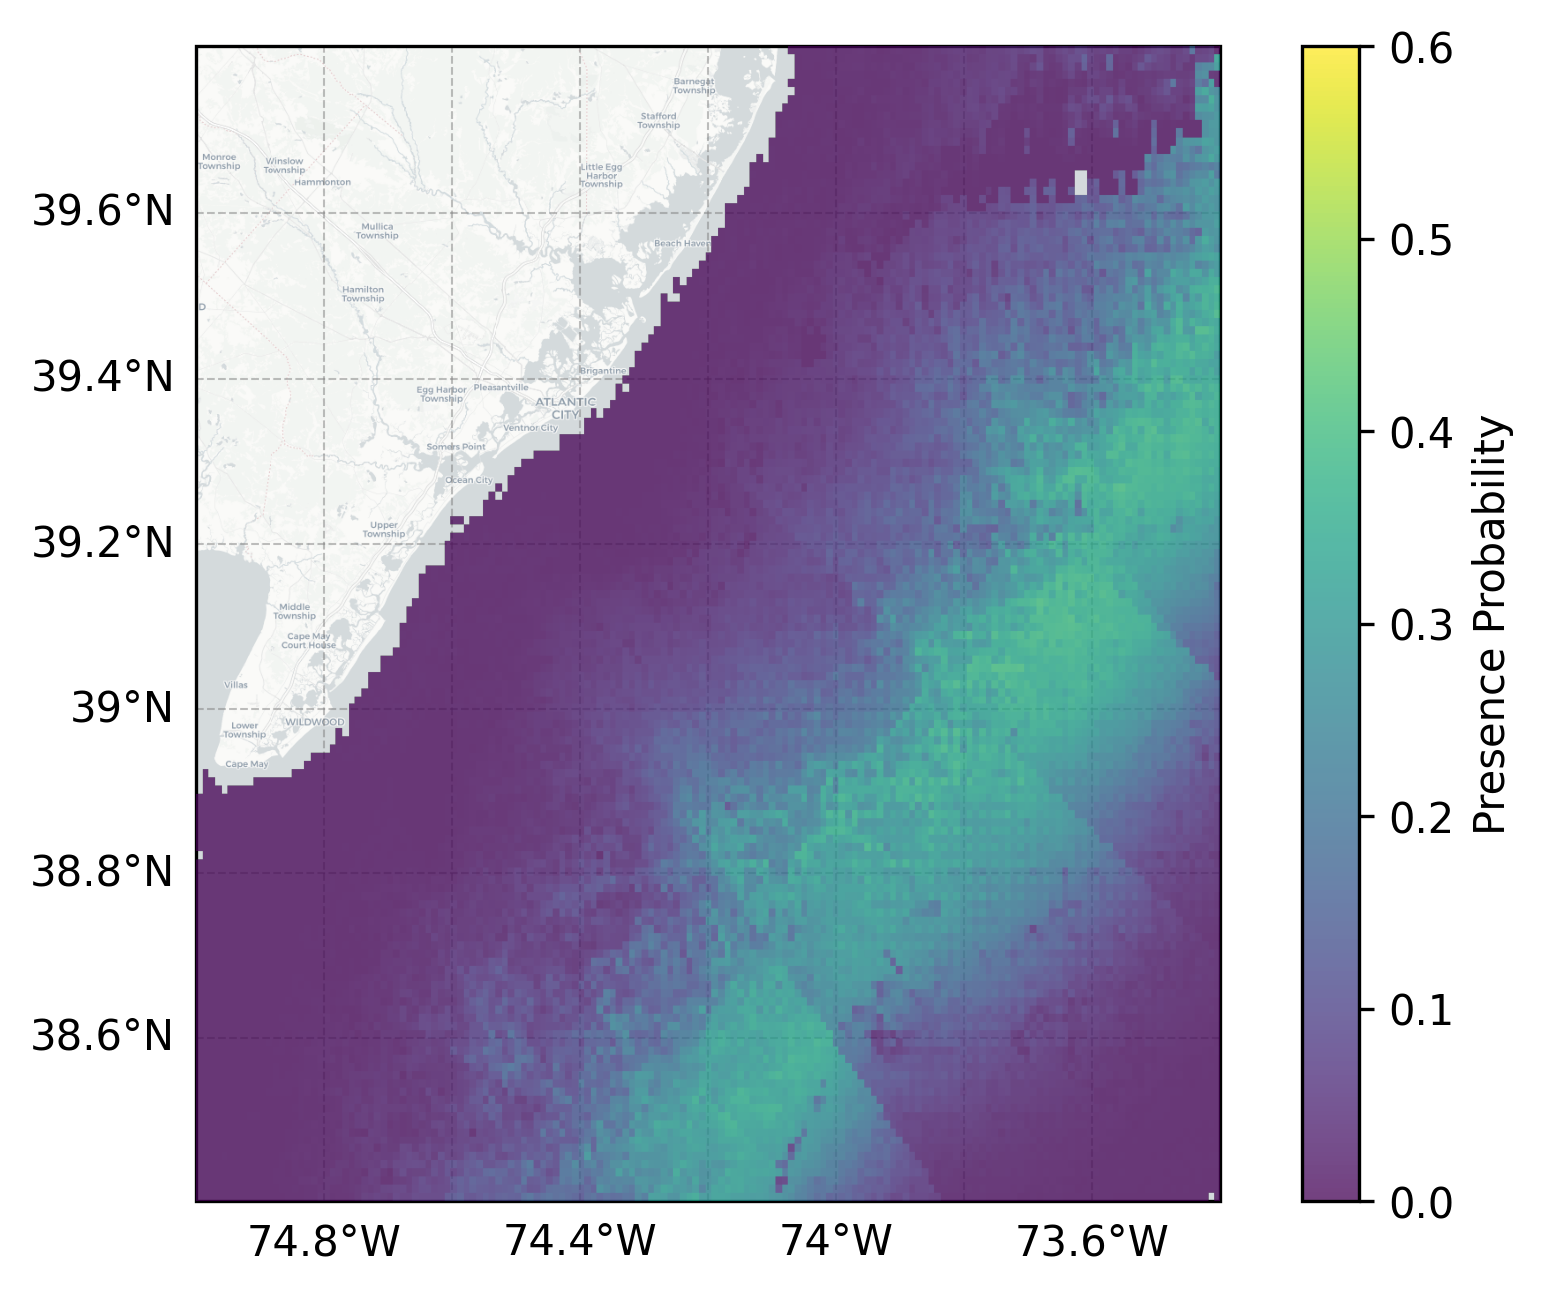

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.io.img_tiles as cimgt
from cartopy.mpl.gridliner import (
    LONGITUDE_FORMATTER,
    LATITUDE_FORMATTER
)
from scipy.ndimage import gaussian_filter
import numpy as np

CARTO_API_KEY = "cb1_3y7p_1_b0a71078580ae84e3004df30"

class CartoDBPositron(cimgt.GoogleTiles):
    def _image_url(self, tile):
        x, y, z = tile
        return (
            f"https://basemaps.cartocdn.com/"
            f"rastertiles/light_all/{z}/{x}/{y}.png"
            f"?key={CARTO_API_KEY}"
        )

f_plot = f1_uq.copy()

#f_plot["prob_presence"] = mean

f = f_plot.rename(
    columns={
        "lat_center": "lat",
        "lon_center": "lon",
        "pi_q05": "p"
    }
)


lat_vals = np.sort(
    f["lat"].unique()
)

lon_vals = np.sort(
    f["lon"].unique()
)

p_grid = (
    f.pivot(
        index="lat",
        columns="lon",
        values="p"
    )
    .reindex(
        index=lat_vals,
        columns=lon_vals
    )
    .to_numpy()
)

# sigma=0 means no smoothing
p_smooth = gaussian_filter(
    p_grid,
    sigma=0
)
tiler = CartoDBPositron()
fig = plt.figure(figsize=(7, 5), dpi=300)
ax = plt.axes(projection=tiler.crs)
extent = [lon_vals.min(), lon_vals.max(), lat_vals.min(), lat_vals.max()]
ax.set_extent(extent, crs=ccrs.PlateCarree())
ax.add_image(tiler, 10)

img = ax.imshow(
    p_smooth,
    extent=extent,
    transform=ccrs.PlateCarree(),
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=0.6,
    alpha=0.75,
    zorder=10
)


gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.5,
    color="gray",
    alpha=0.5,
    linestyle="--"
)

gl.top_labels = False
gl.right_labels = False

gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

gl.xlabel_style = {
    "size": 10,
    "color": "black"
}

gl.ylabel_style = {
    "size": 10,
    "color": "black"
}

plt.colorbar(
    img,
    label="Presence Probability"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.savefig(
    "05.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import xarray as xr
import pandas as pd

vars_needed = ['sst', 'chl_oc3', 'M_WK_G']
nc_path = 'drive/My Drive/PP/averaged_satellite_data_7D.nc'

ds = xr.open_dataset(nc_path)

dfs = []

if 'time' in ds.dims:
    for t in ds['time'].values:
        da_slice = ds.sel(time=t)
        date_str = str(pd.to_datetime(t).date())

        tmp = xr.Dataset({v: da_slice[v] for v in vars_needed}
                         ).to_dataframe().reset_index()
        tmp['time'] = date_str
        dfs.append(tmp)

else:
    date_str = 'unknown'
    tmp = xr.Dataset({v: ds[v] for v in vars_needed}
                     ).to_dataframe().reset_index()
    tmp['time'] = date_str
    dfs.append(tmp)

big_df = pd.concat(dfs, ignore_index=True)

big_df.rename(columns={'longitude': 'lon_center',
                       'latitude' : 'lat_center'}, inplace=True)

print('shape:', big_df.shape)
print(big_df.head())


shape: (1818336, 7)
   lat_center  lon_center       date  sst  chl_oc3  M_WK_G     time
0       38.48      -74.65 2020-01-01  NaN      NaN     NaN  unknown
1       38.48      -74.65 2020-01-08  NaN      NaN     NaN  unknown
2       38.48      -74.65 2020-01-15  NaN      NaN     NaN  unknown
3       38.48      -74.65 2020-01-22  NaN      NaN     NaN  unknown
4       38.48      -74.65 2020-01-29  NaN      NaN     NaN  unknown


In [ ]:
big_df.describe()

,lat_center,lon_center,date,sst,chl_oc3,M_WK_G
count,1.818336e+06,1.818336e+06,1818336,1.692511e+06,1.657500e+06,798087.000000
mean,3.894500e+01,-7.403500e+01,2021-06-26 12:00:00,1.571578e+01,9.817086e-01,0.194145
min,3.848000e+01,-7.465000e+01,2020-01-01 00:00:00,-2.650000e-01,2.873071e-02,0.000000
25%,3.871000e+01,-7.434250e+01,2020-09-28 06:00:00,9.480578e+00,4.428244e-01,0.000000
50%,3.894500e+01,-7.403500e+01,2021-06-26 12:00:00,1.554400e+01,6.705537e-01,0.000000
75%,3.918000e+01,-7.372750e+01,2022-03-24 18:00:00,2.187166e+01,1.089308e+00,0.196557
max,3.941000e+01,-7.342000e+01,2022-12-21 00:00:00,1.638350e+02,9.875800e+01,43.256824
std,2.713393e-01,3.579456e-01,NaN,7.001675e+00,1.408022e+00,0.479789


In [ ]:
big_df['chl_oc3'].quantile(0.99)

np.float32(4.895163)

In [ ]:
big_df = big_df[(big_df.sst.between(0, 27)) &
        (big_df.chl_oc3.between(0,5.2))]

In [ ]:
import pandas as pd
from datetime import datetime
big_df['date'] = pd.to_datetime(big_df['date'])
mask_2020 = big_df['date'].dt.year == 2020
df_2020   = big_df.loc[mask_2020].copy()
season_map = {12:4, 1:4, 2:4,
               3:1, 4:1, 5:1,
               6:2, 7:2, 8:2,
               9:3,10:3,11:3}
df_2020['season'] = df_2020['date'].dt.month.map(season_map)

mask_2021 = big_df['date'].dt.year == 2021
df_2021   = big_df.loc[mask_2021].copy()

df_2021['season'] = df_2021['date'].dt.month.map(season_map)

mask_2022 = big_df['date'].dt.year == 2022
df_2022   = big_df.loc[mask_2022].copy()

df_2022['season'] = df_2022['date'].dt.month.map(season_map)


In [ ]:
df_2022['month_selected'] = df_2022['date'].dt.month
month_rad = 2*np.pi*df_2022["month_selected"]/12
df_2022["month_sin"] = np.sin(month_rad)
df_2022["month_cos"] = np.cos(month_rad)

In [ ]:
d = df_2020[df_2020['date'] == '2020-11-25']

In [ ]:
d.describe()

,lat_center,lon_center,date,sst,chl_oc3,M_WK_G,season
count,11192.000000,11192.000000,11192,11192.000000,11192.000000,0.0,11192.0
mean,38.938728,-74.020186,2020-11-25 00:00:00,14.321344,0.777470,NaN,3.0
min,38.490000,-74.650000,2020-11-25 00:00:00,9.900000,0.217036,NaN,3.0
25%,38.710000,-74.320000,2020-11-25 00:00:00,14.071667,0.417565,NaN,3.0
50%,38.940000,-74.020000,2020-11-25 00:00:00,14.420000,0.523093,NaN,3.0
75%,39.160000,-73.720000,2020-11-25 00:00:00,14.781905,0.798843,NaN,3.0
max,39.410000,-73.420000,2020-11-25 00:00:00,15.832500,5.134599,NaN,3.0
std,0.263644,0.351975,NaN,0.630526,0.681783,NaN,0.0


In [ ]:
df_2022['datetime'] = pd.to_datetime(df_2022['date'])

In [ ]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

grid_lookup = (
    df_2022[['lat_center', 'lon_center']]
    .drop_duplicates()
    .reset_index(drop=True)
)

print(grid_lookup.shape)

(11414, 2)


In [ ]:
geometry = [
    Point(xy) for xy in zip(grid_lookup['lon_center'], grid_lookup['lat_center'])
]
geo_grid = gpd.GeoDataFrame(
    grid_lookup,
    geometry=geometry
)
grid_lookup['distance_to_coastline'] = geo_grid['geometry'].apply(
    calculate_distance_to_coastline,
    coastline=coastline_gdf
)

/tmp/ipykernel_15586/3251035025.py:18: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  nearest_geom = nearest_points(point, coastline.unary_union)[1]


In [ ]:
df_2022_cov = df_2022.merge(
    grid_lookup[['lat_center', 'lon_center', 'distance_to_coastline']],
    on=['lat_center', 'lon_center'],
    how='left'
)

print("Missing distance:", df_2022_cov['distance_to_coastline'].isna().sum())

Missing distance: 0


In [ ]:
df_2022_cov.to_csv('drive/MyDrive/NARW/df_2022.csv',index = False)

In [ ]:
weekly_cov_maps = {}

for date, g in df_2022_cov.groupby('date'):
    weekly_cov_maps[pd.Timestamp(date)] = g.copy().reset_index(drop=True)

print("Number of weekly maps:", len(weekly_cov_maps))

# first_date = sorted(weekly_cov_maps.keys())[0]
# print("First week:", first_date)
# print(weekly_cov_maps[first_date].head())

Number of weekly maps: 51


In [ ]:
import torch

def predict_presence_map(
    f_week,
    model,
    sc_pres,
    PRES,
    DET,
    date_col='date',
    lon_col='lon_center',
    lat_col='lat_center'
):
    f_week = f_week.copy()
    f_week[date_col] = pd.to_datetime(f_week[date_col])

    missing_cols = [c for c in PRES if c not in f_week.columns]
    if len(missing_cols) > 0:
        raise ValueError(f"Missing PRES columns: {missing_cols}")

    valid_mask = f_week[PRES].notna().all(axis=1)

    f_week['p_presence'] = np.nan

    if valid_mask.sum() == 0:
        return f_week

    xp = torch.from_numpy(
        sc_pres.transform(f_week.loc[valid_mask, PRES])
    ).float()

    xd_dummy = torch.zeros((valid_mask.sum(), len(DET)), dtype=torch.float32)

    lon = torch.tensor(
        f_week.loc[valid_mask, lon_col].values,
        dtype=torch.float32
    )
    lat = torch.tensor(
        f_week.loc[valid_mask, lat_col].values,
        dtype=torch.float32
    )
    month = torch.tensor(
        f_week.loc[valid_mask, date_col].dt.month.values - 1,
        dtype=torch.float32
    )

    st = torch.stack([lon, lat, month], dim=1)

    model.eval()
    with torch.no_grad():
        pi_hat, _ = model(xp, xd_dummy, st)

    f_week.loc[valid_mask, 'p_presence'] = pi_hat.cpu().numpy()

    return f_week

In [ ]:
weekly_pred_maps = {}

for date, f_week in weekly_cov_maps.items():
    f_pred = predict_presence_map(
        f_week=f_week,
        model=model,
        sc_pres=sc_pres,
        PRES=PRES,
        DET=DET,
        date_col='date'
    )

    weekly_pred_maps[date] = f_pred

print("Finished prediction for", len(weekly_pred_maps), "weeks.")

Finished prediction for 51 weeks.


In [ ]:
import joblib
joblib.dump(weekly_pred_maps, "drive/MyDrive/NARW/weekly_pred_maps.pkl")

['drive/MyDrive/NARW/weekly_pred_maps.pkl']

In [ ]:
weekly_pred_maps[pd.Timestamp('2022-02-02')].describe()

,lat_center,lon_center,date,sst,chl_oc3,M_WK_G,season,month_selected,month_sin,month_cos,datetime,distance_to_coastline,p_presence
count,11141.000000,11141.000000,11141,11141.000000,11141.000000,10849.000000,11141.0,11141.0,1.114100e+04,11141.0,11141,11141.000000,10849.000000
mean,38.928632,-74.014589,2022-02-02 00:00:00,4.868090,1.046928,0.274855,4.0,2.0,8.660254e-01,0.5,2022-02-02 00:00:00,60.092524,0.111141
min,38.480000,-74.650000,2022-02-02 00:00:00,0.000000,0.079343,0.000000,4.0,2.0,8.660254e-01,0.5,2022-02-02 00:00:00,0.996611,0.000402
25%,38.700000,-74.310000,2022-02-02 00:00:00,3.377500,0.595637,0.000000,4.0,2.0,8.660254e-01,0.5,2022-02-02 00:00:00,37.867873,0.031342
50%,38.930000,-74.010000,2022-02-02 00:00:00,4.830000,0.855143,0.000000,4.0,2.0,8.660254e-01,0.5,2022-02-02 00:00:00,59.643784,0.087305
75%,39.150000,-73.710000,2022-02-02 00:00:00,6.206666,1.216555,0.275115,4.0,2.0,8.660254e-01,0.5,2022-02-02 00:00:00,81.507524,0.151885
max,39.410000,-73.420000,2022-02-02 00:00:00,11.054999,5.199141,5.256298,4.0,2.0,8.660254e-01,0.5,2022-02-02 00:00:00,129.442264,0.585221
std,0.264204,0.349622,NaN,1.809795,0.760661,0.578244,0.0,0.0,1.784208e-13,0.0,NaN,28.725811,0.103216


In [ ]:
import pandas as pd
import numpy as np

q95_records = []

for date, f_week in weekly_pred_maps.items():
    q95 = f_week['p_presence'].quantile(0.95)

    q95_records.append({
        'date': pd.Timestamp(date),
        'p_presence_q95': q95,
        'n_grid': len(f_week),
        'p_presence_mean': f_week['p_presence'].mean(),
        'p_presence_max': f_week['p_presence'].max()
    })

weekly_q95_df = pd.DataFrame(q95_records).sort_values('date').reset_index(drop=True)

In [ ]:
weekly_q95_df.to_csv("drive/MyDrive/NARW/weekly_presence_probability_q95.csv", index=False)

,timestamp,chl_oc3,sst,M_WK_G,datetime_utc,M_WK,elevation,depth,temperature,salinity,oxygen_concentration,Whale_Status_Code,lon,lat,datetime,month,season,distance_to_coastline,month_sin,month_cos
0,2020-11-20 10:45:16+00:00,3.047778,15.257978,0.108274,2020-11-20 10:45:16+00:00,38.0,-26.0,2.193203,14.5741,31.990088,250.98,1,-74.1587,39.2727,2020-11-20 10:45:16+00:00,11,3,23.885011,-5.000000e-01,0.866025
1,2020-11-22 02:29:09+00:00,0.835666,15.778320,0.174413,2020-11-22 02:29:09+00:00,38.0,-23.0,2.788662,14.7752,32.260773,250.45,1,-74.1812,39.1810,2020-11-22 02:29:09+00:00,11,3,28.000095,-5.000000e-01,0.866025
2,2020-11-22 03:00:16+00:00,0.763327,15.822998,0.164612,2020-11-22 03:00:16+00:00,248.0,-23.0,1.826033,14.8638,32.208557,260.78,1,-74.1829,39.1789,2020-11-22 03:00:16+00:00,11,3,28.059398,-5.000000e-01,0.866025
3,2020-11-22 03:30:16+00:00,0.728270,15.822998,0.127844,2020-11-22 03:30:16+00:00,418.0,-23.0,2.540563,14.8565,32.208710,257.37,1,-74.1818,39.1764,2020-11-22 03:30:16+00:00,11,3,28.322970,-5.000000e-01,0.866025
4,2020-11-22 03:45:16+00:00,0.713434,15.822998,0.111713,2020-11-22 03:45:16+00:00,248.0,-23.0,4.287182,14.8170,32.254642,250.58,1,-74.1812,39.1752,2020-11-22 03:45:16+00:00,11,3,28.454070,-5.000000e-01,0.866025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4374,2022-06-05 21:45:29+00:00,0.968229,18.487976,0.000000,2022-06-05 21:45:29+00:00,451.0,-22.0,1.726834,18.6380,32.109024,290.75,0,-74.4599,38.9097,2022-06-05 21:45:29+00:00,6,2,29.979399,1.224647e-16,-1.000000
4375,2022-06-05 22:00:29+00:00,0.968229,18.487976,0.000000,2022-06-05 22:00:29+00:00,451.0,-22.0,1.726834,18.6380,32.109024,290.75,0,-74.4591,38.9108,2022-06-05 22:00:29+00:00,6,2,29.944303,1.224647e-16,-1.000000
4376,2022-06-05 22:45:29+00:00,0.968229,18.487976,0.000000,2022-06-05 22:45:29+00:00,451.0,-24.0,2.262744,18.6248,32.150833,293.47,0,-74.4567,38.9143,2022-06-05 22:45:29+00:00,6,2,29.827539,1.224647e-16,-1.000000
4377,2022-06-05 23:00:29+00:00,0.968229,18.487976,0.000000,2022-06-05 23:00:29+00:00,451.0,-24.0,1.419180,18.5962,32.119267,290.26,0,-74.4559,38.9154,2022-06-05 23:00:29+00:00,6,2,29.794996,1.224647e-16,-1.000000


In [ ]:
hourly_truth = make_hourly_detection_truth(
    detect_df=data[data['Whale_Status_Code']==1],
    time_col='datetime_utc'
)

In [ ]:
data[data['Whale_Status_Code']==1]

,timestamp,chl_oc3,sst,M_WK_G,datetime_utc,M_WK,elevation,depth,temperature,salinity,oxygen_concentration,Whale_Status_Code,lon,lat,datetime,month,season,distance_to_coastline,month_sin,month_cos
0,2020-11-20 10:45:16+00:00,3.047778,15.257978,0.108274,2020-11-20 10:45:16+00:00,38.0,-26.0,2.193203,14.5741,31.990088,250.98,1,-74.1587,39.2727,2020-11-20 10:45:16+00:00,11,3,23.885011,-0.5,8.660254e-01
1,2020-11-22 02:29:09+00:00,0.835666,15.778320,0.174413,2020-11-22 02:29:09+00:00,38.0,-23.0,2.788662,14.7752,32.260773,250.45,1,-74.1812,39.1810,2020-11-22 02:29:09+00:00,11,3,28.000095,-0.5,8.660254e-01
2,2020-11-22 03:00:16+00:00,0.763327,15.822998,0.164612,2020-11-22 03:00:16+00:00,248.0,-23.0,1.826033,14.8638,32.208557,260.78,1,-74.1829,39.1789,2020-11-22 03:00:16+00:00,11,3,28.059398,-0.5,8.660254e-01
3,2020-11-22 03:30:16+00:00,0.728270,15.822998,0.127844,2020-11-22 03:30:16+00:00,418.0,-23.0,2.540563,14.8565,32.208710,257.37,1,-74.1818,39.1764,2020-11-22 03:30:16+00:00,11,3,28.322970,-0.5,8.660254e-01
4,2020-11-22 03:45:16+00:00,0.713434,15.822998,0.111713,2020-11-22 03:45:16+00:00,248.0,-23.0,4.287182,14.8170,32.254642,250.58,1,-74.1812,39.1752,2020-11-22 03:45:16+00:00,11,3,28.454070,-0.5,8.660254e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,2022-03-01 09:24:36+00:00,0.638437,7.488525,0.114054,2022-03-01 09:24:36+00:00,248.0,-46.0,34.455215,6.7141,33.558480,311.02,1,-73.9912,38.6875,2022-03-01 09:24:36+00:00,3,1,82.844845,1.0,6.123234e-17
100,2022-03-01 09:39:36+00:00,0.638437,7.488525,0.113541,2022-03-01 09:39:36+00:00,248.0,-49.0,2.431506,6.7096,33.557780,311.48,1,-73.9931,38.6898,2022-03-01 09:39:36+00:00,3,1,82.542866,1.0,6.123234e-17
101,2022-03-01 10:24:36+00:00,0.492363,7.488525,0.109563,2022-03-01 10:24:36+00:00,51.0,-50.0,1.885659,6.6340,33.540863,311.77,1,-73.9989,38.6966,2022-03-01 10:24:36+00:00,3,1,81.643210,1.0,6.123234e-17
102,2022-03-01 10:39:36+00:00,0.492363,7.654266,0.107303,2022-03-01 10:39:36+00:00,248.0,-50.0,11.363310,6.6270,33.539480,311.60,1,-74.0008,38.6988,2022-03-01 10:39:36+00:00,3,1,81.351292,1.0,6.123234e-17


In [ ]:
data2 = pd.read_csv('drive/My Drive/PP/trial_27.csv')

In [ ]:
present = data2[data2['right'] == 'present']

In [ ]:
present = data2[(data2['right'] == 'present') | (data2['right'] == 'maybe')]

In [ ]:
present[(present['datetime_utc']>= '2022-01-01')  & (present['datetime_utc'] <= '2022-12-31')]

,timestamp,datetime_utc,sei,fin,right,humpback,lat,lon,elevation,dist_shore,...,depth,oxygen_concentration,salinity,temperature,M_WK,M_WK_G,datetime,month,season,Whale_Status_Code
9045,2022-01-20 15:09:04,2022-01-20 15:09:04,absent,present,maybe,absent,39.1046,-74.0954,-28.0,50815.034795,...,2.490959,291.76,33.375350,7.6330,NaN,NaN,2022-01-20 15:09:04,1,4,0
9054,2022-01-20 18:09:04,2022-01-20 18:09:04,absent,present,present,absent,39.0813,-74.0548,-37.0,56342.368452,...,2.818459,291.76,33.375350,7.6330,NaN,NaN,2022-01-20 18:09:04,1,4,1
9055,2022-01-20 18:24:04,2022-01-20 18:24:04,absent,maybe,present,absent,39.0790,-74.0514,-37.0,56841.695417,...,2.818459,291.76,33.375350,7.6330,NaN,NaN,2022-01-20 18:24:04,1,4,1
9056,2022-01-20 19:09:04,2022-01-20 19:09:04,absent,absent,present,absent,39.0719,-74.0465,-32.0,57949.959661,...,2.431423,291.76,33.375350,7.6330,NaN,NaN,2022-01-20 19:09:04,1,4,1
9057,2022-01-20 19:24:04,2022-01-20 19:24:04,absent,present,present,absent,39.0699,-74.0451,-32.0,58263.953686,...,2.431423,291.76,33.375350,7.6330,NaN,NaN,2022-01-20 19:24:04,1,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12089,2022-03-13 20:39:36,2022-03-13 20:39:36,absent,absent,maybe,absent,39.2136,-74.2285,-23.0,29311.957445,...,2.103899,308.86,32.864906,5.7825,248.0,0.156105,2022-03-13 20:39:36,3,1,0
12090,2022-03-13 20:54:36,2022-03-13 20:54:36,absent,absent,maybe,absent,39.2140,-74.2270,-23.0,29383.650836,...,2.103899,308.86,32.864906,5.7825,248.0,0.156105,2022-03-13 20:54:36,3,1,0
12308,2022-03-31 19:26:14,2022-03-31 19:26:14,absent,absent,maybe,absent,39.2496,-74.1921,-18.0,29007.473256,...,7.423070,301.99,31.847305,6.6512,NaN,NaN,2022-03-31 19:26:14,3,1,0
12309,2022-03-31 19:41:14,2022-03-31 19:41:14,absent,absent,maybe,absent,39.2496,-74.1932,-18.0,28906.494286,...,17.733545,299.14,31.897740,6.6102,NaN,NaN,2022-03-31 19:41:14,3,1,0


In [ ]:
import pandas as pd
import numpy as np

def make_daily_presence_truth_2022(
    present,
    time_col='timestamp',
    start_date='2022-01-01',
    end_date='2022-12-31',
    output_col='whale_present'
):
    """
    Generate daily whale presence ground truth for 2022.

    Rule:
    If at least one whale detection/presence point occurs within a natural day,
    whale_present = 1. Otherwise whale_present = 0.

    Output:
        date, whale_present, n_detection
    """

    df = present.copy()
    df[time_col] = pd.to_datetime(df[time_col])

    # 只保留日期，不保留小时分钟秒
    df['date'] = df[time_col].dt.floor('D')

    # 只保留 2022 范围内的 detection/presence
    start_date = pd.to_datetime(start_date)
    end_date = pd.to_datetime(end_date)

    df = df[
        (df['date'] >= start_date) &
        (df['date'] <= end_date)
    ].copy()

    # 完整 2022 daily 日期表
    full_days = pd.DataFrame({
        'date': pd.date_range(start=start_date, end=end_date, freq='D')
    })

    # 每天 detection/presence 点数量
    detected_days = (
        df.groupby('date')
          .size()
          .reset_index(name='n_detection')
    )

    detected_days[output_col] = 1

    # merge 到完整日期表，没有 detection 的天补 0
    daily_truth = full_days.merge(
        detected_days,
        on='date',
        how='left'
    )

    daily_truth['n_detection'] = daily_truth['n_detection'].fillna(0).astype(int)
    daily_truth[output_col] = daily_truth[output_col].fillna(0).astype(int)

    return daily_truth

In [ ]:
daily_truth_2022 = make_daily_presence_truth_2022(
    present=present,
    time_col='timestamp'   # 如果你的时间列不是 timestamp，这里改掉
)

In [ ]:
daily_truth_2022.to_csv('drive/My Drive/NARW/daily_truth.csv',index= False)

In [ ]:
# geometry = [Point(xy) for xy in zip(f1['lon_center'], f1['lat_center'])]
# geo_df = gpd.GeoDataFrame(f1, geometry=geometry)
# # Calculate distance to coastline
# f1['distance_to_coastline'] = geo_df['geometry'].apply(calculate_distance_to_coastline, coastline=coastline_gdf)

/tmp/ipykernel_4521/3251035025.py:18: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  nearest_geom = nearest_points(point, coastline.unary_union)[1]


In [ ]:
# import numpy as np, pandas as pd, torch
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

# df_sim = data.copy()

# train_df = df_sim[df_sim['timestamp'] < '2022-02-01']

# #PRES = ["M_WK_G","sst","chl_oc3","distance_to_coastline",
# #        "month_sin","month_cos"]
# PRES = ["M_WK_G","sst","chl_oc3","distance_to_coastline",
#         "month_sin","month_cos"]
# DET  = ["depth","temperature","salinity","oxygen_concentration",
#         "elevation","distance_to_coastline"]
# sc_pres = StandardScaler().fit(train_df[PRES])
# sc_det  = StandardScaler().fit(train_df[DET ])

# state_dict, best_loss, sec = train_one_sim(
#         train_df, PRES, DET,
#         sc_pres, sc_det,
#         epoch=25, lr=5e-4, batch=256,
#         patience=20, verbose=True,SEED = 42)
# print(f"training time = {sec:.2f}s, best_loss = {best_loss:.4f}")


# model = ZIB_MLP(len(PRES), len(DET))
# model.load_state_dict(state_dict)
# model.eval()
# test_df = df_sim[df_sim['timestamp'] >= '2022-02-01']
# xp = torch.from_numpy(sc_pres.transform(test_df[PRES])).float()
# xd = torch.from_numpy(sc_det .transform(test_df[DET ])).float()
# with torch.no_grad():
#     pi, phi = model(xp, xd)
#     y_prob  = (pi*phi).cpu().numpy()      # P(Y=1)
#     y_true  = test_df["Whale_Status_Code"].to_numpy()

# print("Test NLL   :", log_loss(y_true, y_prob))
# print("Test AUC   :", roc_auc_score(y_true, y_prob))
# print("Test Brier :", brier_score_loss(y_true, y_prob))


ep  20 | avg loss = 0.3399
training time = 8.56s, best_loss = 0.2268
Test NLL   : 0.08973575283978648
Test AUC   : 0.8147304832713755
Test Brier : 0.01720834390254453


In [ ]:
# test_df['pi'] = pi.cpu().numpy()
# present = test_df[test_df['Whale_Status_Code']==1]
# print(-float(np.mean(np.log(np.clip(present['pi'], 1e-12, 1.0)))))
# float(np.mean((present['pi'] - 1.0)**2))

3.334491491317749


/tmp/ipython-input-418417884.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df['pi'] = pi.cpu().numpy()


0.9205813407897949

In [ ]:
# import numpy as np, pandas as pd, torch
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

# df_sim = data.copy()

# train_df = df_sim[df_sim['timestamp'] < '2022-02-01']

# #PRES = ["M_WK_G","sst","chl_oc3","distance_to_coastline","month_sin","month_cos"]
# PRES = ["M_WK_G","sst","chl_oc3","distance_to_coastline","month_sin","month_cos"]
# DET  = ["depth","temperature","salinity","oxygen_concentration",
#         "elevation","distance_to_coastline"]
# sc_pres = StandardScaler().fit(train_df[PRES])
# sc_det  = StandardScaler().fit(train_df[DET ])

# state_dict, best_loss, sec = train_one_sim_gp_raw(
#         train_df, PRES, DET,
#         sc_pres, sc_det,
#         epoch=25, lr=6e-4, batch=256,
#         patience=20, verbose=True, SEED = 42)
# print(f"training time = {sec:.2f}s, best_loss = {best_loss:.4f}")


Epoch  10 | Loss = 1.8268
Epoch  20 | Loss = 1.5296
training time = 73.58s, best_loss = 1.4336


In [ ]:
import torch, numpy as np, pandas as pd
model = ZIB_MLP_GP_RAW(len(PRES), len(DET))
model.load_state_dict(state_dict)
model.eval()
xp = torch.from_numpy(sc_pres.transform(f1[PRES])).float()

xd_dummy = torch.zeros((len(f1), len(DET)), dtype=torch.float32)

# --- 3. 构造 GP 的空间+时间输入 (st) ---
lon   = torch.tensor(f1["lon_center"].values, dtype=torch.float32)
lat   = torch.tensor(f1["lat_center"].values, dtype=torch.float32)
month = torch.tensor(f1["datetime"].dt.month.values - 1, dtype=torch.float32)
st    = torch.stack([lon, lat, month], dim=1)  # shape: (N,3)
model.eval()
with torch.no_grad():
    pi_hat, _ = model(xp, xd_dummy, st)

f1['p_presence'] = pi_hat.cpu().numpy()



In [ ]:
f1.describe()

,lon_center,lat_center,sst,chl_oc3,M_WK_G,date,season,month_selected,distance_to_coastline,month_sin,month_cos,datetime,p_presence
count,17772.000000,17772.000000,17772.000000,17772.000000,17459.000000,17772,17772.0,17772.0,17772.000000,1.777200e+04,17772.0,17772,17459.000000
mean,-74.070080,38.995292,6.445230,1.503076,0.175428,2022-02-01 00:00:00,4.0,2.0,51.855378,8.660254e-01,0.5,2022-02-01 00:00:00,0.329157
min,-75.000000,38.400000,1.721667,0.388508,0.000000,2022-02-01 00:00:00,4.0,2.0,0.013671,8.660254e-01,0.5,2022-02-01 00:00:00,0.000739
25%,-74.400000,38.670000,5.036045,0.970022,0.016587,2022-02-01 00:00:00,4.0,2.0,25.035356,8.660254e-01,0.5,2022-02-01 00:00:00,0.065619
50%,-74.030000,38.950000,6.268774,1.356473,0.082637,2022-02-01 00:00:00,4.0,2.0,48.404794,8.660254e-01,0.5,2022-02-01 00:00:00,0.144127
75%,-73.710000,39.290000,7.556865,1.893141,0.224342,2022-02-01 00:00:00,4.0,2.0,74.858355,8.660254e-01,0.5,2022-02-01 00:00:00,0.625558
max,-73.400000,39.800000,13.013181,5.195021,4.413944,2022-02-01 00:00:00,4.0,2.0,137.922832,8.660254e-01,0.5,2022-02-01 00:00:00,0.999418
std,0.427899,0.383556,1.744685,0.722616,0.266958,NaN,0.0,0.0,32.116911,2.461434e-13,0.0,NaN,0.320924


In [ ]:
f_base = f1.copy()
f_base.to_csv('drive/My Drive/PP/base_map_3.csv', index = False)

In [ ]:
f_time = f1.copy()
f_time.to_csv('drive/My Drive/PP/time_map_3.csv', index = False)

In [ ]:
f_dist = f1.copy()
f_dist.to_csv('drive/My Drive/PP/dist_map_9.csv', index = False)

In [ ]:
f_chl = f1.copy()
f_chl.to_csv('drive/My Drive/PP/chl_map_9.csv', index = False)

In [ ]:
f_sst = f1.copy()
f_sst.to_csv('drive/My Drive/PP/sst_map_9.csv', index = False)

In [ ]:
f_mwkg = f1.copy()
f_mwkg.to_csv('drive/My Drive/PP/mwkg_map_9.csv', index = False)

In [ ]:
f1['p_presence'] = f_time['p_presence']-f_base['p_presence']
N = f1['p_presence'].values.size

In [ ]:
np.mean(f1['p_presence']), np.std(f1['p_presence'])

(np.float32(-0.072397344), 0.15933804214000702)

In [ ]:
f1.to_csv('drive/My Drive/PP/May.csv', index = False)

In [ ]:
# ------- EM-like 损失（与你之前 custom_loss 等价）-------
def em_loss(pi, phi, y, eps=1e-6):
    # clamp 防止 log(0)
    pi  = pi.clamp(eps, 1 - eps)
    phi = phi.clamp(eps, 1 - eps)
    y   = y.float()
    # E-step: 后验 w = P(S=1 | Y=0, X)   （S=“结构性0”= presence=0）
    w = (pi * (1 - phi)) / ((1 - pi) + pi * (1 - phi) + eps)
    w = w.clamp(eps, 1 - eps).detach()  # 关键：detach，EM 的 E 步不回传
    # M-step: 两头的带权交叉熵
    loss_pi  = - ( y * torch.log(pi) + (1 - y) * ( w*torch.log(pi) + (1 - w)*torch.log(1 - pi) ) ).mean()
    loss_phi = - ( y * torch.log(phi) + (1 - y) * w * torch.log(1 - phi) ).mean()
    return loss_pi + loss_phi

def train_one_sim(
    df_train, PRES, DET, sc_pres, sc_det,
    epoch=25, lr=1.0, batch=None, patience=20, verbose=True, SEED=42,
    label_col="Whale_Status_Code",
):
    torch.manual_seed(SEED); np.random.seed(SEED)

    xp = torch.from_numpy(sc_pres.transform(df_train[PRES])).float()
    xd = torch.from_numpy(sc_det .transform(df_train[DET ])).float()
    y  = torch.tensor(df_train[label_col].to_numpy(), dtype=torch.float32)

    net = ZIBLogit(len(PRES), len(DET))
    opt = torch.optim.LBFGS(
        net.parameters(), lr=lr, max_iter=100, history_size=20,
        line_search_fn="strong_wolfe", tolerance_change=1e-12
    )

    best = float("inf"); best_state=None; stall=0
    tic = time.time()
    for ep in range(1, epoch+1):
        def closure():
            opt.zero_grad()
            pi, phi = net(xp, xd)
            loss = em_loss(pi, phi, y)      # ← 改这里：用 EM 损失
            loss.backward()
            return loss
        nll_em = opt.step(closure).item()
        if nll_em < best - 1e-9:
            best, stall = nll_em, 0
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        else:
            stall += 1
        if verbose and ep % 5 == 0:
            print(f"[LBFGS ep {ep:03d}] train EM-Loss={nll_em:.6f}")
        if stall >= patience:
            if verbose: print("Early stopped."); break

    if best_state is not None:
        net.load_state_dict(best_state)
    sec = time.time() - tic
    return net.state_dict(), float(best), sec


In [ ]:
import numpy as np, pandas as pd, torch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

df_sim = data.copy()
train_df = df_sim[df_sim['timestamp'] < '2022-02-01']
test_df  = df_sim[df_sim['timestamp'] >= '2022-02-01']

PRES = ["M_WK_G","sst","chl_oc3","distance_to_coastline","month_sin","month_cos"]
DET  = ["depth","temperature","salinity","oxygen_concentration","elevation","distance_to_coastline"]

sc_pres = StandardScaler().fit(train_df[PRES])
sc_det  = StandardScaler().fit(train_df[DET ])

state_dict, best_loss, sec = train_one_sim(
    train_df, PRES, DET, sc_pres, sc_det,
    epoch=25, lr=1.0, patience=20, verbose=True, SEED=42,
    label_col="Whale_Status_Code"
)
print(f"training time = {sec:.2f}s, best_loss = {best_loss:.4f}")

# --- 测试集检测指标（基于 q=πφ）---
model = ZIBLogit(len(PRES), len(DET))
model.load_state_dict(state_dict); model.eval()

xp = torch.from_numpy(sc_pres.transform(test_df[PRES])).float()
xd = torch.from_numpy(sc_det .transform(test_df[DET ])).float()
with torch.no_grad():
    pi, phi = model(xp, xd)
    y_prob  = (pi*phi).cpu().numpy().ravel()      # q = P(Y=1)
    y_true  = test_df["Whale_Status_Code"].to_numpy()

print("Test NLL   :", log_loss(y_true, y_prob))
print("Test AUC   :", roc_auc_score(y_true, y_prob))
print("Test Brier :", brier_score_loss(y_true, y_prob))


TypeError: train_one_sim() got an unexpected keyword argument 'label_col'

In [ ]:
import torch, numpy as np, pandas as pd

zib = ZIBLogit(len(PRES), len(DET))
zib.load_state_dict(state_dict)
zib.eval()

xp = torch.from_numpy(sc_pres.transform(f1[PRES])).float()

if set(DET).issubset(f1.columns):
    xd_np = sc_det.transform(f1[DET]).astype(np.float32)
else:
    xd_np = np.zeros((len(f1), len(DET)), dtype=np.float32)

xd = torch.from_numpy(xd_np).float()

with torch.no_grad():
    pi_hat, _ = zib(xp, xd)    # 只取 π
f1['p_presence'] = pi_hat.cpu().numpy().ravel()


In [ ]:
f1.describe()

,lon_center,lat_center,sst,chl_oc3,M_WK_G,date,season,month_selected,distance_to_coastline,month_sin,month_cos,datetime,p_presence
count,17772.000000,17772.000000,17772.000000,17772.000000,17459.000000,17772,17772.0,17772.0,17772.000000,1.777200e+04,17772.0,17772,1.745900e+04
mean,-74.070080,38.995292,6.445230,1.503076,0.175428,2022-02-01 00:00:00,4.0,2.0,51.855378,8.660254e-01,0.5,2022-02-01 00:00:00,3.699354e-01
min,-75.000000,38.400000,1.721667,0.388508,0.000000,2022-02-01 00:00:00,4.0,2.0,0.013671,8.660254e-01,0.5,2022-02-01 00:00:00,2.166042e-07
25%,-74.400000,38.670000,5.036045,0.970022,0.016587,2022-02-01 00:00:00,4.0,2.0,25.035356,8.660254e-01,0.5,2022-02-01 00:00:00,3.202020e-03
50%,-74.030000,38.950000,6.268774,1.356473,0.082637,2022-02-01 00:00:00,4.0,2.0,48.404794,8.660254e-01,0.5,2022-02-01 00:00:00,1.266549e-01
75%,-73.710000,39.290000,7.556865,1.893141,0.224342,2022-02-01 00:00:00,4.0,2.0,74.858355,8.660254e-01,0.5,2022-02-01 00:00:00,8.608091e-01
max,-73.400000,39.800000,13.013181,5.195021,4.413944,2022-02-01 00:00:00,4.0,2.0,137.922832,8.660254e-01,0.5,2022-02-01 00:00:00,9.999728e-01
std,0.427899,0.383556,1.744685,0.722616,0.266958,NaN,0.0,0.0,32.116911,2.461434e-13,0.0,NaN,4.110568e-01


In [ ]:
new_data = pd.read_csv('drive/My Drive/PP/trial_27.csv')
new_data['datetime_utc'] = pd.to_datetime(new_data['datetime_utc'])
new_data = new_data[new_data['datetime_utc'].dt.year == 2022]
narw0 = new_data[new_data.month == 3]
narw0 = narw0[(narw0['datetime_utc'] >= "2022-03-01")&(narw0['datetime_utc'] <= "2022-04-01")]
narw = new_data[new_data['right'] == 'present']
#narw = new_data[new_data['detection'] == 1]
narw = narw[narw.month == 3]
narw = narw[(narw.timestamp >= "2022-03-01")&(narw.timestamp <= "2022-04-01")]

In [ ]:
new_data = pd.read_csv('drive/My Drive/PP/NEFSC Aerial Data 2020-2025.csv', encoding='latin-1')

In [ ]:
narw = new_data[new_data['SPCODE']=='RIWH']
narw['datetime_utc'] = pd.to_datetime(narw['DATETIME_ET'],format = '%d-%b-%y %I.%M.%S.%f %p',errors = 'coerce')

/tmp/ipython-input-884166404.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  narw['datetime_utc'] = pd.to_datetime(narw['DATETIME_ET'],format = '%d-%b-%y %I.%M.%S.%f %p',errors = 'coerce')


In [ ]:
narw2022 = narw[narw['datetime_utc'].dt.year == 2022]
narw0 = narw2022[narw2022['datetime_utc'].dt.month == 5]
narw0 = narw0[narw0['LONGITUDE']>-72]

In [ ]:
pip install contextily

In [ ]:
f1.describe()

,lon_center,lat_center,sst,chl_oc3,M_WK_G,date,season,month_selected,distance_to_coastline,month_sin,month_cos,datetime,p_presence
count,17331.000000,17331.000000,17331.000000,17331.000000,17154.000000,17331,17331.0,17331.0,17331.000000,1.733100e+04,1.733100e+04,17331,17154.000000
mean,-74.059013,38.989062,9.395535,1.394706,0.280552,2022-04-01 00:00:00,1.0,4.0,53.044774,8.660254e-01,-5.000000e-01,2022-04-01 00:00:00,0.190453
min,-75.000000,38.400000,8.139808,0.353594,0.000000,2022-04-01 00:00:00,1.0,4.0,0.015072,8.660254e-01,-5.000000e-01,2022-04-01 00:00:00,0.000003
25%,-74.380000,38.670000,8.994329,0.637333,0.000000,2022-04-01 00:00:00,1.0,4.0,26.768954,8.660254e-01,-5.000000e-01,2022-04-01 00:00:00,0.079981
50%,-74.010000,38.950000,9.251250,0.988923,0.017196,2022-04-01 00:00:00,1.0,4.0,49.528789,8.660254e-01,-5.000000e-01,2022-04-01 00:00:00,0.165692
75%,-73.700000,39.280000,9.681479,1.816980,0.286039,2022-04-01 00:00:00,1.0,4.0,75.708622,8.660254e-01,-5.000000e-01,2022-04-01 00:00:00,0.279952
max,-73.400000,39.800000,13.217500,5.199310,14.340700,2022-04-01 00:00:00,1.0,4.0,137.922832,8.660254e-01,-5.000000e-01,2022-04-01 00:00:00,0.561701
std,0.423167,0.379386,0.556781,1.043271,0.606293,NaN,0.0,0.0,31.632915,2.433679e-13,1.110255e-16,NaN,0.126691


In [ ]:
f1['p_presence'] = f_time['p_presence']-f_base['p_presence']

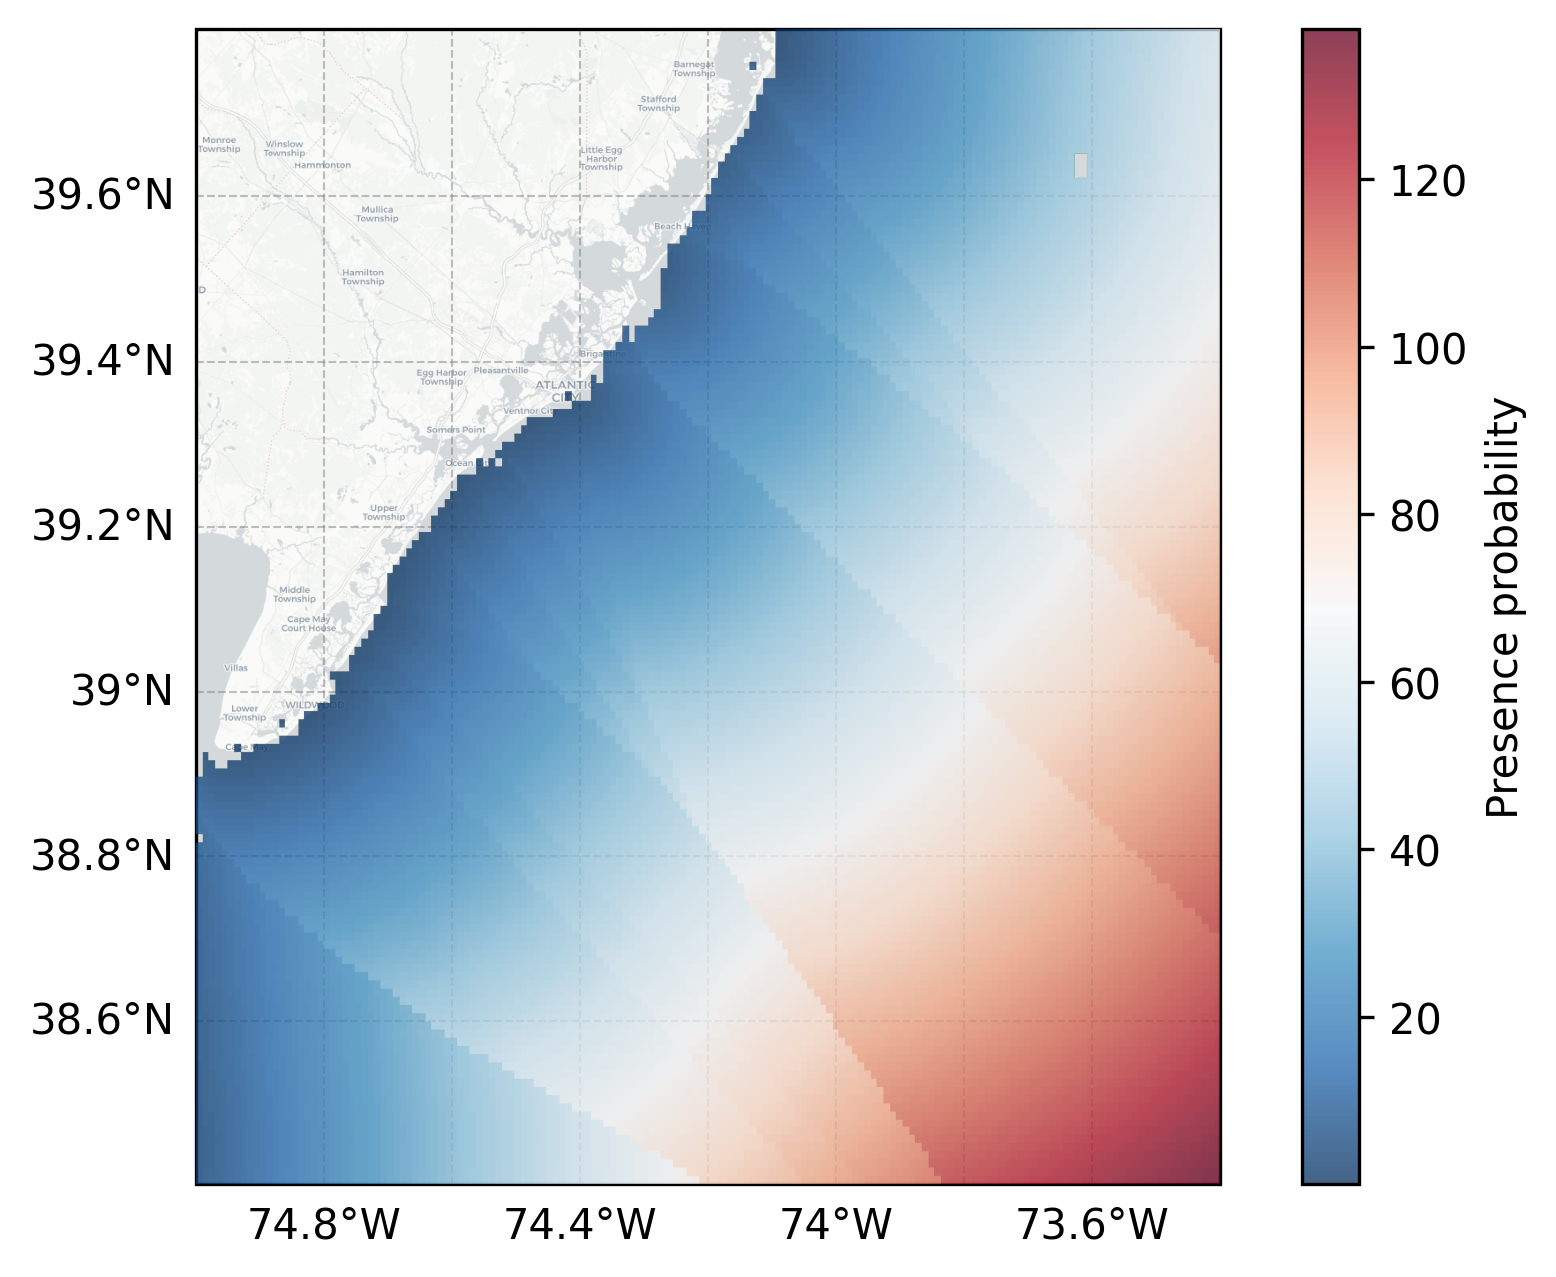

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.io.img_tiles as cimgt
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from scipy.ndimage import gaussian_filter
import numpy as np
import matplotlib.colors as mcolors
import pandas as pd

# ---- 0. 定义一个好看的底图类 (CartoDB 灰白极简风) ----
# Cartopy 自带的 OSM 是绿色的，这里我们要“欺骗”它去下载 CartoDB 的瓦片
class CartoDBPositron(cimgt.GoogleTiles):
    def _image_url(self, tile):
        x, y, z = tile
        url = 'https://a.basemaps.cartocdn.com/light_all/{}/{}/{}.png'.format(z, x, y)
        return url

# ---- 1. 数据准备 (保持不变) ----
# 假设 f1 已经加载
f = f1.rename(columns={'lat_center':'lat', 'lon_center':'lon', 'distance_to_coastline':'p'})
lat_vals = np.sort(f['lat'].unique())
lon_vals = np.sort(f['lon'].unique())
p_grid = f.pivot(index='lat', columns='lon', values='p').values
# 平滑
p_smooth = gaussian_filter(p_grid, sigma=0)

# ---- 2. Duke 配色 (保持不变) ----
duke_colors = [
    "#081d58", "#253494", "#225ea8", "#1d91c0", "#41b6c4",
    "#7fcdbb", "#c7e9b4", "#ffffcc", "#ffeda0", "#fed976",
    "#feb24c", "#fd8d3c", "#f03b20", "#bd0026", "#800026"
]
duke_like_cmap = mcolors.LinearSegmentedColormap.from_list("duke_like", duke_colors[::-1], N=256)

# ---- 3. 设置地图源 (核心修改：换肤) ----
# 选项 A: 使用刚才定义的灰色极简图 (推荐，最能突出数据)
tiler = CartoDBPositron()

# 选项 B: 使用谷歌卫星图 (如果你喜欢深色背景)
# tiler = cimgt.GoogleTiles(style='satellite')

# ---- 4. 绘图 ----
fig = plt.figure(figsize=(7, 5), dpi=300)
ax = plt.axes(projection=tiler.crs)

# 设置范围
extent = [lon_vals.min(), lon_vals.max(), lat_vals.min(), lat_vals.max()]
ax.set_extent(extent, crs=ccrs.PlateCarree())

# 添加底图 (level=10, 数字越大越清晰越慢)
ax.add_image(tiler, 10)

# 绘制热图
img = ax.imshow(p_smooth,
           extent=extent,
           transform=ccrs.PlateCarree(),
           origin='lower',
           cmap="RdBu_r",  # 用回 Duke 配色
           #vmin=-0.4, vmax=0.4,
           alpha=0.75,           # 稍微不那么透明一点，让颜色更实
           zorder=10)

gl = ax.gridlines(draw_labels=True,
                  linewidth=0.5, color='gray', alpha=0.5, linestyle='--')

# 设置刻度显示位置
gl.top_labels = False   # 上方不显示经度
gl.right_labels = False # 右侧不显示纬度
# 格式化刻度 (加上 °E, °N 符号)
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
# 设置字体大小
gl.xlabel_style = {'size': 10, 'color': 'black'}
gl.ylabel_style = {'size': 10, 'color': 'black'}

plt.colorbar(img, label='Presence probability')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
#plt.savefig("/content/drive/MyDrive/zib_fig/Feb_ZIB.png", dpi=300, bbox_inches='tight')
plt.show()